<a href="https://colab.research.google.com/github/osuchn/weather-prediction/blob/main/Projekt_przewidywanie_pogody.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temat 3 - Przewidywanie wystąpienia opadów następnego dnia

**Cel projektu**: przewidywanie, czy następnego dnia wystąpi deszcz na podstawie dostępnych danych meteorologicznych.


1. Przygotowanie środowiska oraz wczytanie danych.
2. Eksploracyjna analiza danych (EDA) i identyfikacja brakujących wartości.
3. Wspólne przygotowanie danych dla wszystkich modeli.
4. Utworzenie przypadku bazowego poprzez usunięcie rekordów zawierających braki danych.
5. Budowa i ocena modeli dla przypadku bazowego.
6. Zastosowanie metody Simple Imputer.
7. Zastosowanie metody Iterative Imputer.
8. Zastosowanie metody KNN Imputer.
9. Porównanie wyników modeli przy użyciu różnych metod imputacji.
10. Analiza wyników oraz sformułowanie końcowych wniosków.
11. Zadanie dodatkowe

## 1. Przygotowanie środowiska i wczytanie danych


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import seaborn as sns
import time
import matplotlib.colors as mcolors
import matplotlib.cm as cm

from scipy.stats import chi2_contingency
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.feature_selection import RFE



In [ ]:
data = pd.read_csv('pogoda.csv')

print(f'Liczba wierszy: {data.shape[0]}')
print(f'Liczba kolumn: {data.shape[1]}')

data.head(20)


Liczba wierszy: 145460
Liczba kolumn: 23


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No
5,2008-12-06,Albury,14.6,29.7,0.2,NaN,NaN,WNW,56.0,W,...,55.0,23.0,1009.2,1005.4,NaN,NaN,20.6,28.9,No,No
6,2008-12-07,Albury,14.3,25.0,0.0,NaN,NaN,W,50.0,SW,...,49.0,19.0,1009.6,1008.2,1.0,NaN,18.1,24.6,No,No
7,2008-12-08,Albury,7.7,26.7,0.0,NaN,NaN,W,35.0,SSE,...,48.0,19.0,1013.4,1010.1,NaN,NaN,16.3,25.5,No,No
8,2008-12-09,Albury,9.7,31.9,0.0,NaN,NaN,NNW,80.0,SE,...,42.0,9.0,1008.9,1003.6,NaN,NaN,18.3,30.2,No,Yes
9,2008-12-10,Albury,13.1,30.1,1.4,NaN,NaN,W,28.0,S,...,58.0,27.0,1007.0,1005.7,NaN,NaN,20.1,28.2,Yes,No


Już przy podglądzie pierwszych rekordów widać, że zbiór zawiera liczne braki danych. Szczególnie problematyczne są kolumny takie jak `Evaporation`, `Sunshine`, `Cloud9am` oraz `Cloud3pm`, ale braki występują również w części pozostałych zmiennych.


## 2. Eksploracyjna analiza danych (EDA)


In [ ]:
print('\nInformacje o danych:\n')
data.info()

print('\nBrakujące wartości w danych:\n')
display(data.isnull().sum().sort_values(ascending=False))



Informacje o danych:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9

,0
Sunshine,69835
Evaporation,62790
Cloud3pm,59358
Cloud9am,55888
Pressure9am,15065
Pressure3pm,15028
WindDir9am,10566
WindGustDir,10326
WindGustSpeed,10263
Humidity3pm,4507


Analizowany zbiór zawiera zarówno zmienne numeryczne, jak i jakościowe. Jedynie część kolumn nie ma braków, a kilka cech zawiera ich bardzo dużo, co uzasadnia późniejsze porównanie różnych metod radzenia sobie z brakującymi danymi.


In [ ]:
categorical_columns = ['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']

for column in categorical_columns:
    print(f'{column}:')
    print(data[column].unique())


WindGustDir:
['W' 'WNW' 'WSW' 'NE' 'NNW' 'N' 'NNE' 'SW' nan 'ENE' 'SSE' 'S' 'NW' 'SE'
 'ESE' 'E' 'SSW']
WindDir9am:
['W' 'NNW' 'SE' 'ENE' 'SW' 'SSE' 'S' 'NE' nan 'SSW' 'N' 'WSW' 'ESE' 'E'
 'NW' 'WNW' 'NNE']
WindDir3pm:
['WNW' 'WSW' 'E' 'NW' 'W' 'SSE' 'ESE' 'ENE' 'NNW' 'SSW' 'SW' 'SE' 'N' 'S'
 'NNE' nan 'NE']
RainToday:
['No' 'Yes' nan]
RainTomorrow:
['No' 'Yes' nan]


W kolumnach jakościowych nie widać alternatywnych oznaczeń braków takich jak ? czy puste ciągi znaków. Najważniejszy problem pozostają standardowe wartości NaN, w tym także braki w kolumnie docelowej RainTomorrow.


In [ ]:
data.describe()


,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,143975.000000,144199.000000,142199.000000,82670.000000,75625.000000,135197.000000,143693.000000,142398.000000,142806.000000,140953.000000,130395.00000,130432.000000,89572.000000,86102.000000,143693.000000,141851.00000
mean,12.194034,23.221348,2.360918,5.468232,7.611178,40.035230,14.043426,18.662657,68.880831,51.539116,1017.64994,1015.255889,4.447461,4.509930,16.990631,21.68339
std,6.398495,7.119049,8.478060,4.193704,3.785483,13.607062,8.915375,8.809800,19.029164,20.795902,7.10653,7.037414,2.887159,2.720357,6.488753,6.93665
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.50000,977.100000,0.000000,0.000000,-7.200000,-5.40000
25%,7.600000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.90000,1010.400000,1.000000,2.000000,12.300000,16.60000
50%,12.000000,22.600000,0.000000,4.800000,8.400000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.60000,1015.200000,5.000000,5.000000,16.700000,21.10000
75%,16.900000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.40000,1020.000000,7.000000,7.000000,21.600000,26.40000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.00000,1039.600000,9.000000,9.000000,40.200000,46.70000


Opis statystyczny wskazuje m.in. na silną asymetrię zmiennej Rainfall oraz obecność wartości odstających w kilku cechach numerycznych. To cenna informacja przed etapem modelowania i późniejszym skalowaniem cech.


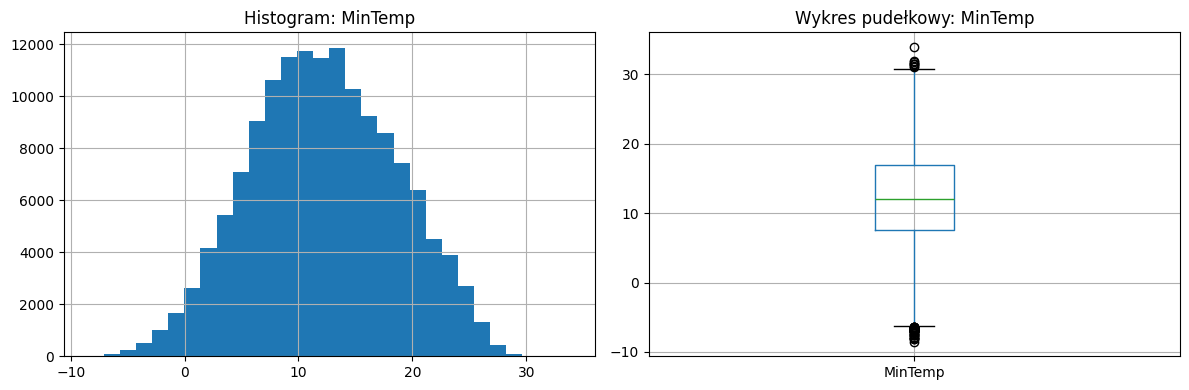

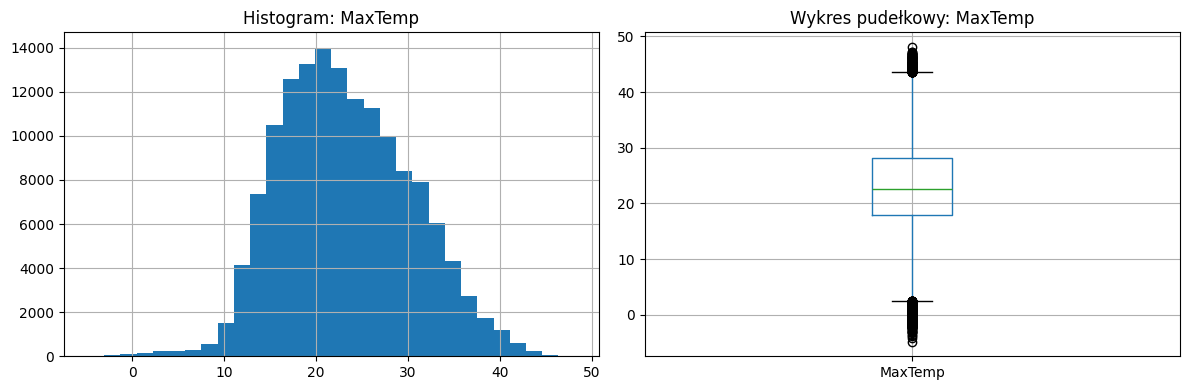

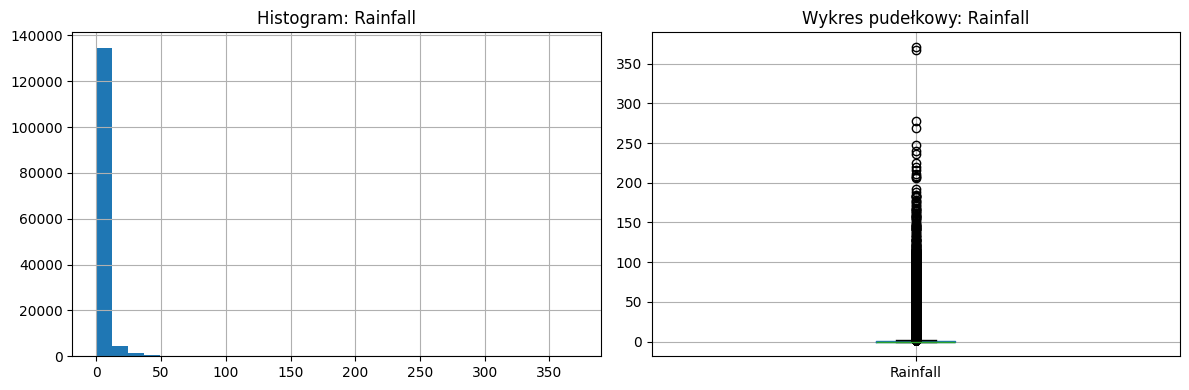

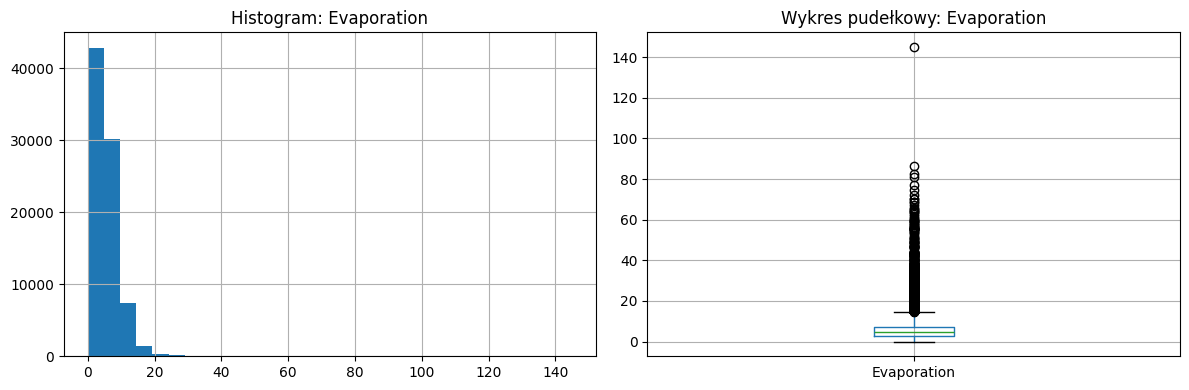

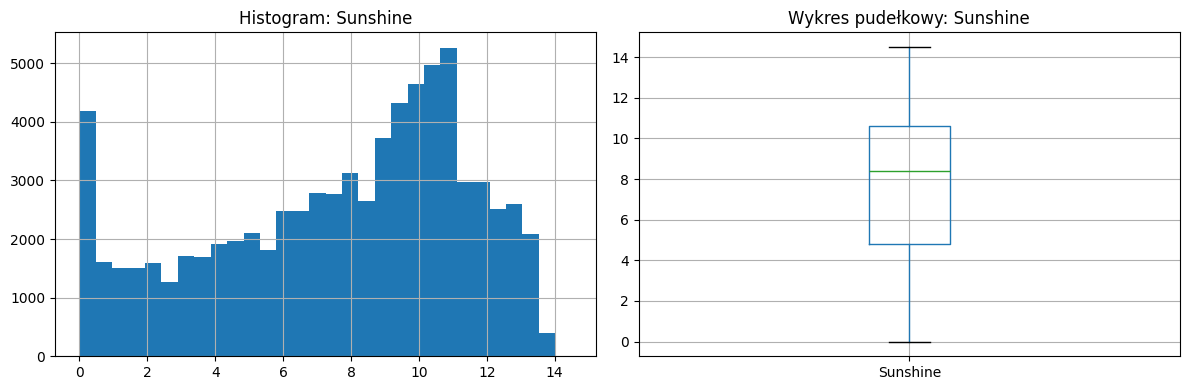

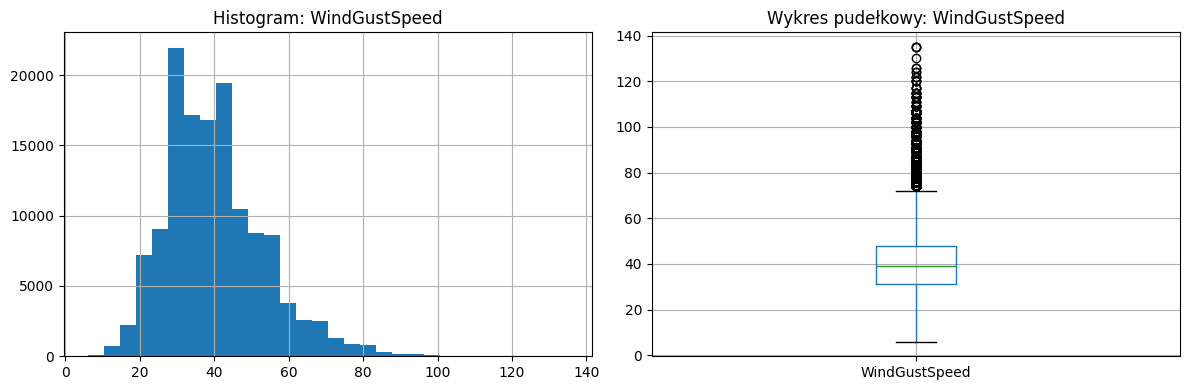

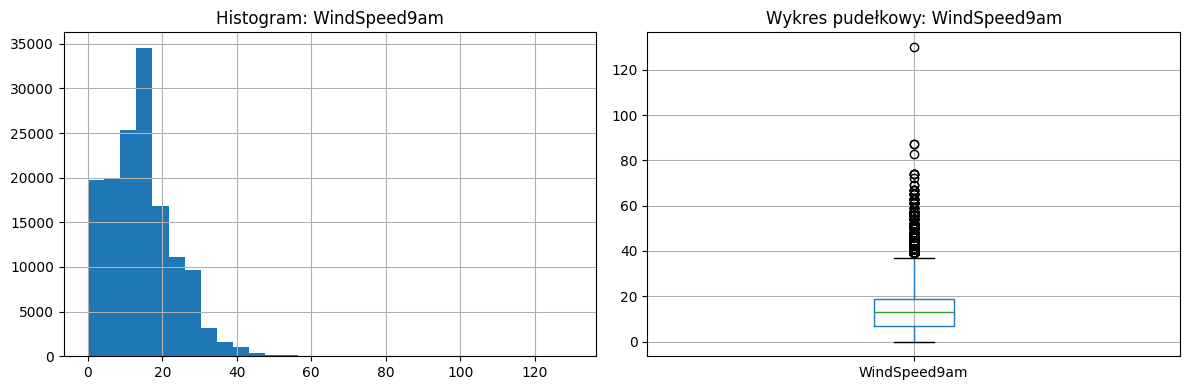

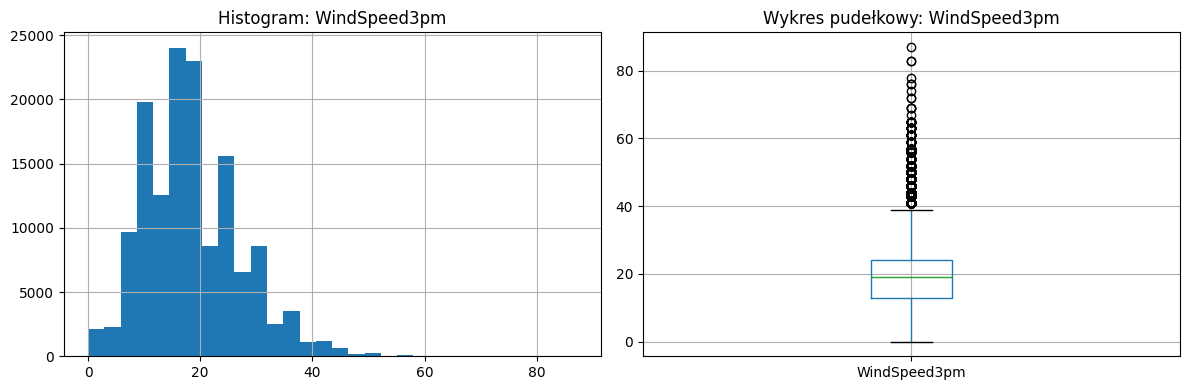

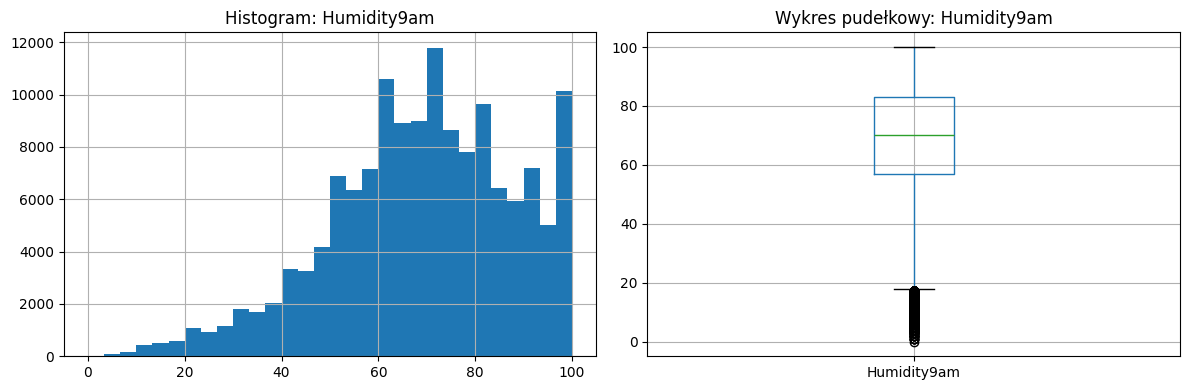

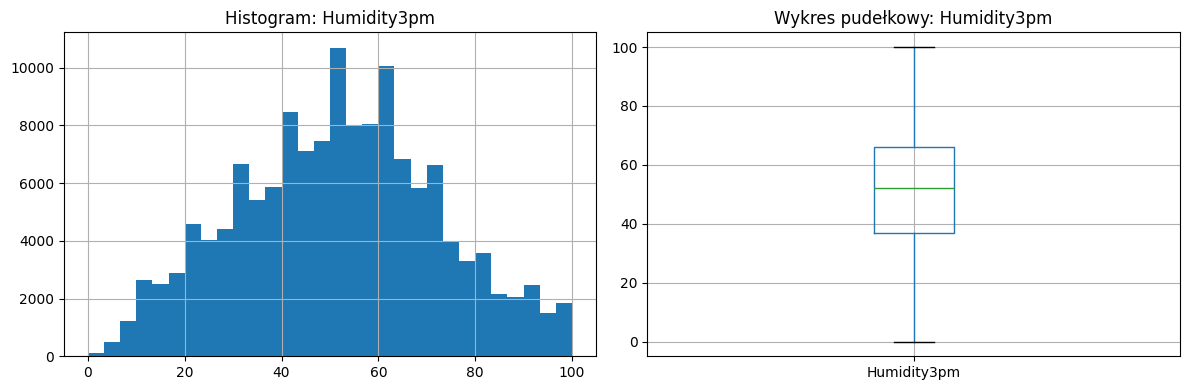

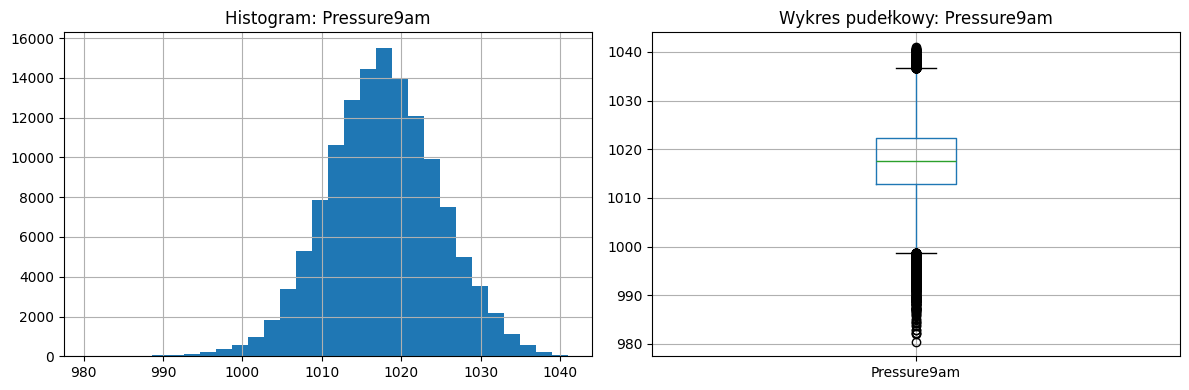

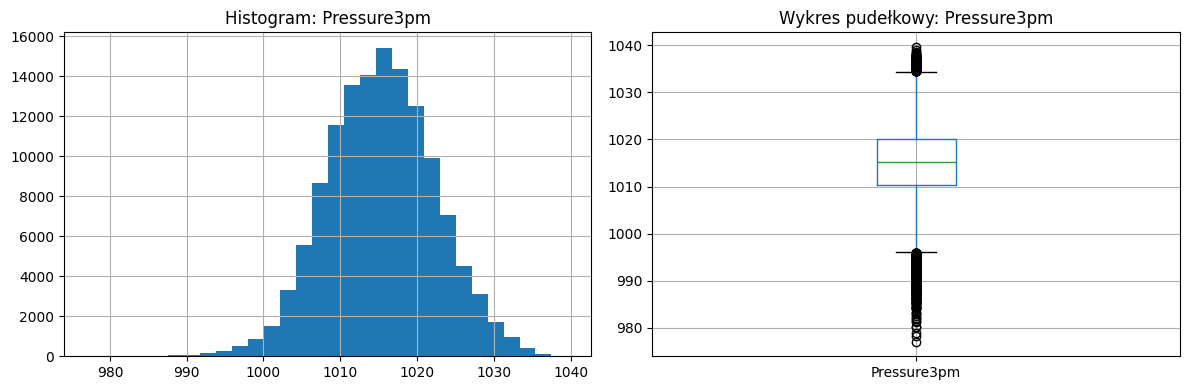

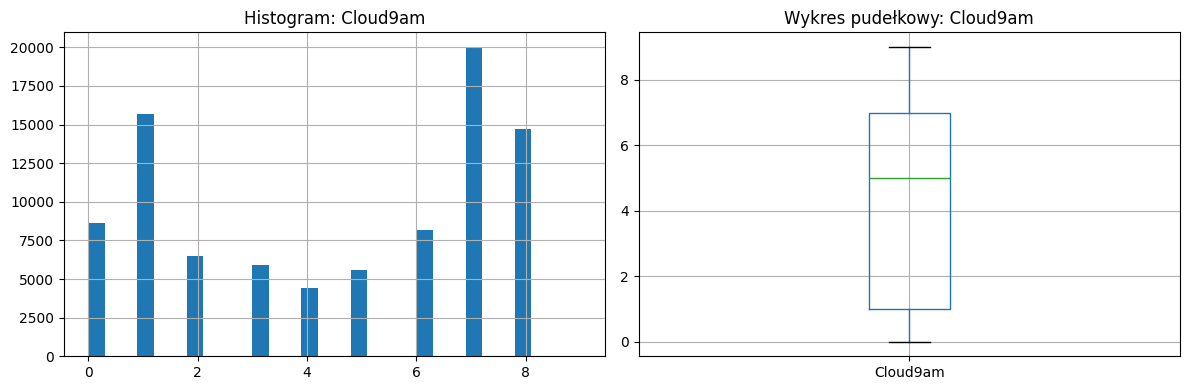

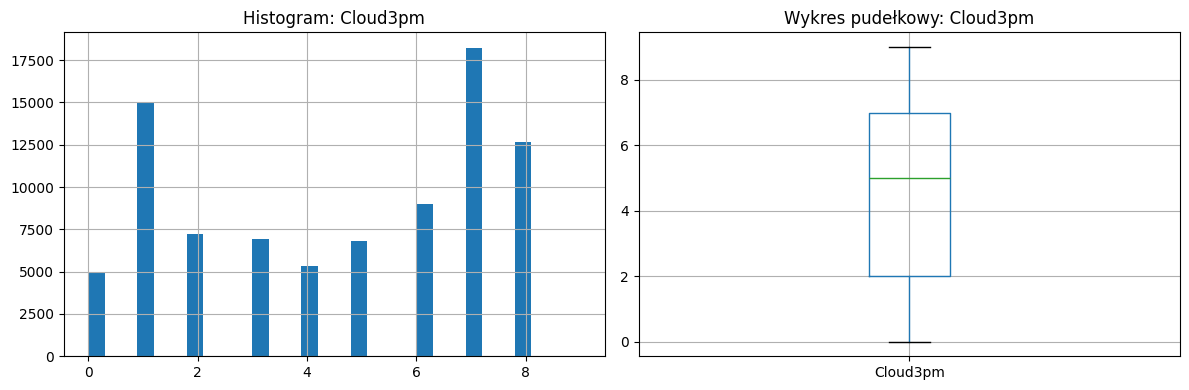

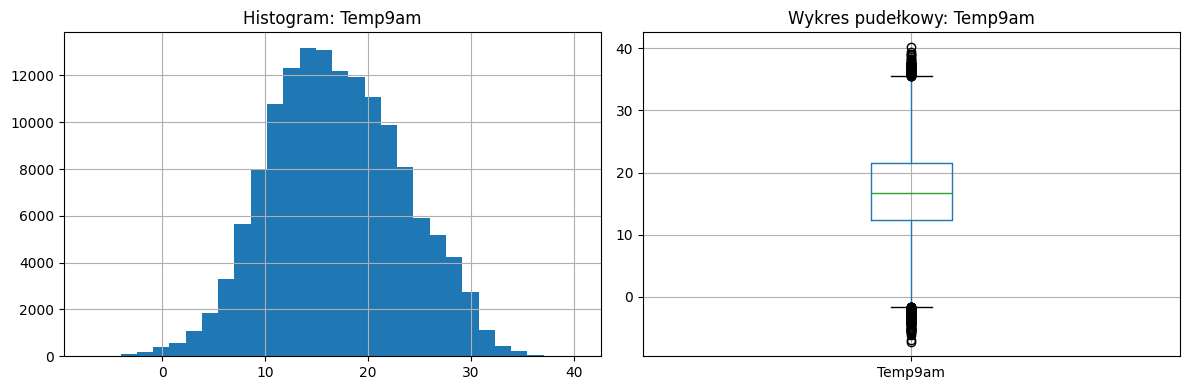

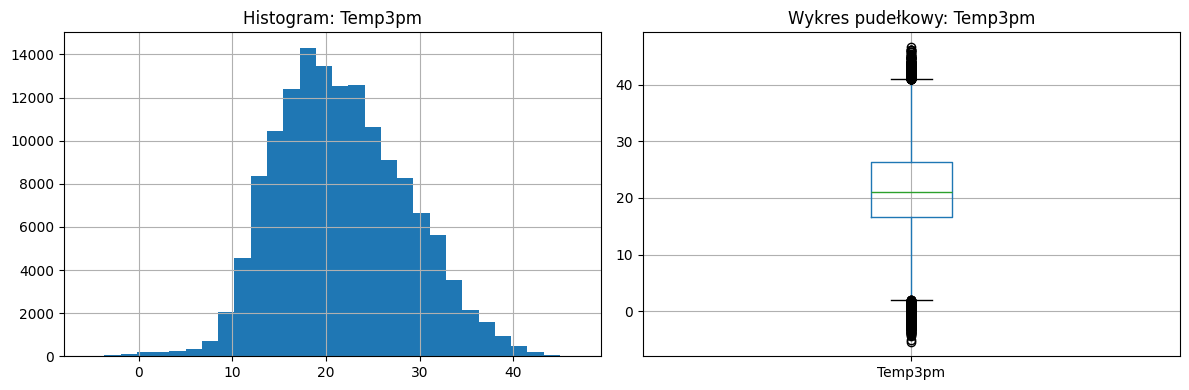

In [ ]:
numeric_columns = data.select_dtypes(include=['number']).columns

for column in numeric_columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    data[column].hist(bins=30, ax=axes[0])
    axes[0].set_title(f'Histogram: {column}')
    data.boxplot(column=column, ax=axes[1])
    axes[1].set_title(f'Wykres pudełkowy: {column}')
    plt.tight_layout()
    plt.show()


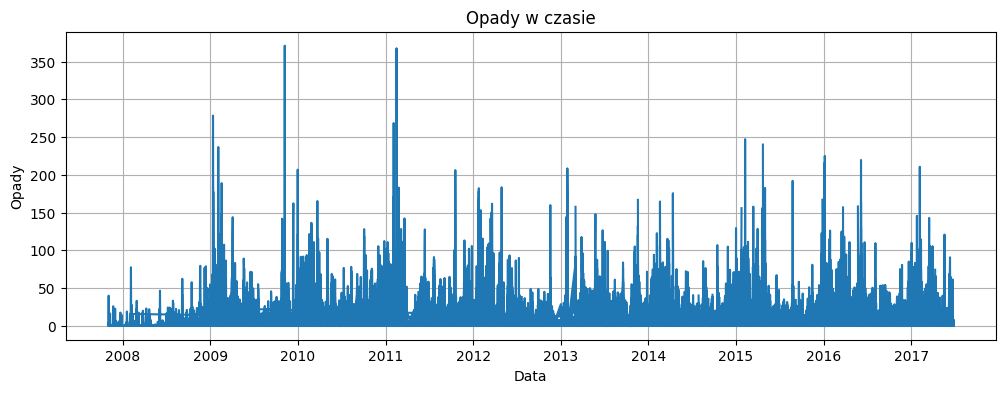

In [ ]:
data['Date'] = pd.to_datetime(data['Date'])

plt.figure(figsize=(12,4))

plt.plot(data['Date'], data['Rainfall'])

plt.title('Opady w czasie')
plt.xlabel('Data')
plt.ylabel('Opady')

plt.grid(True)
plt.show()



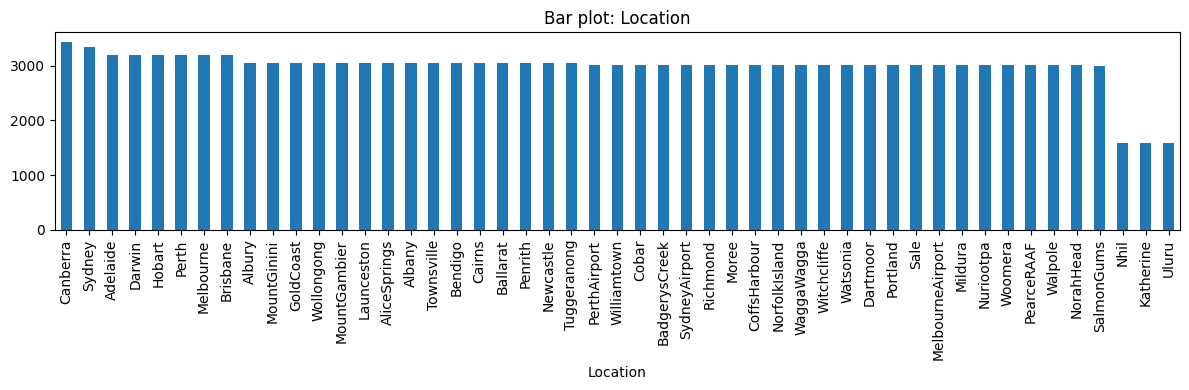

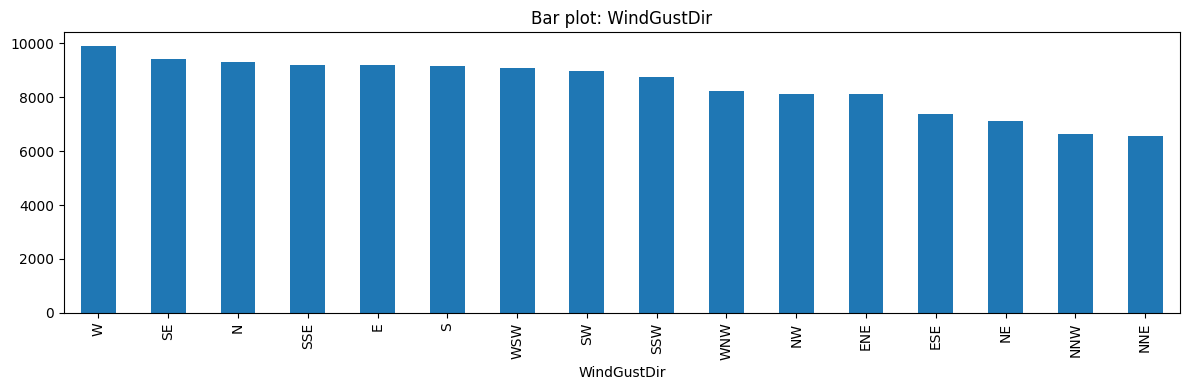

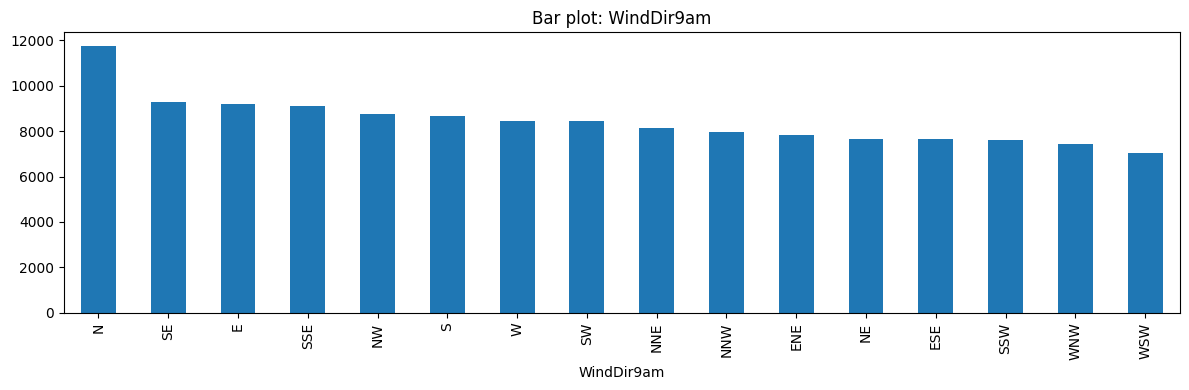

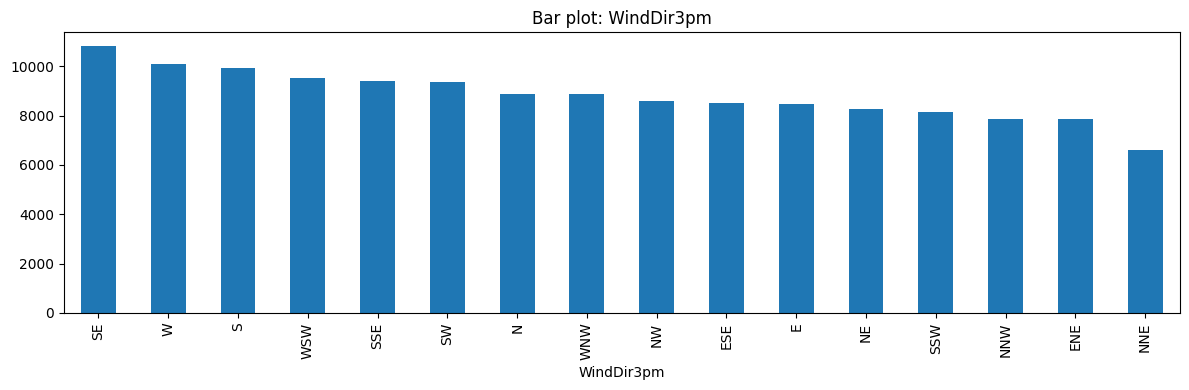

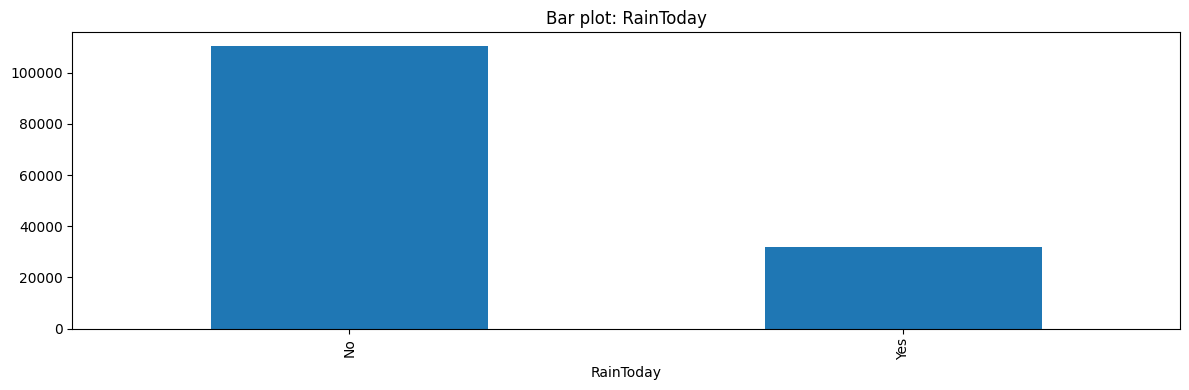

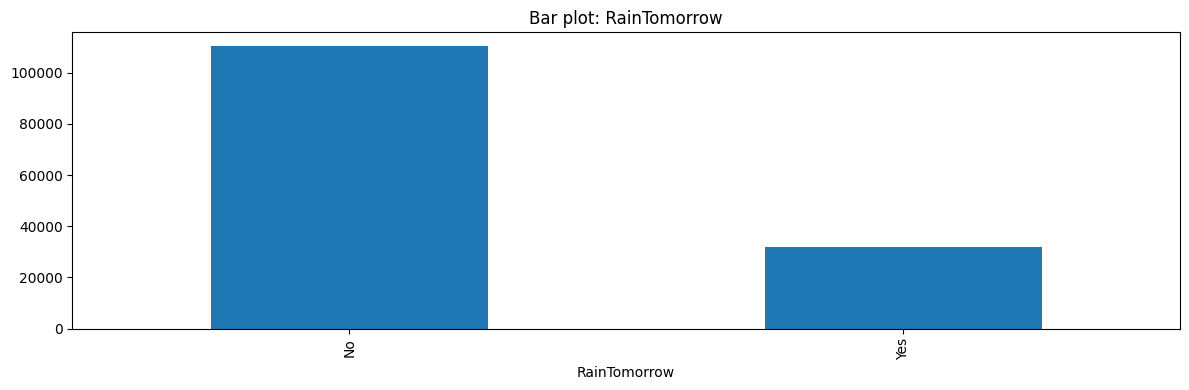

In [ ]:
categorical_columns = data.select_dtypes(exclude=['number']).columns

for column in categorical_columns:

    if column == 'Date':
        continue

    fig, ax = plt.subplots(figsize=(12, 4))

    data[column].value_counts().plot(
        kind='bar',
        ax=ax
    )

    ax.set_title(f'Bar plot: {column}')

    plt.tight_layout()

    plt.show()

Histogramy względem klas

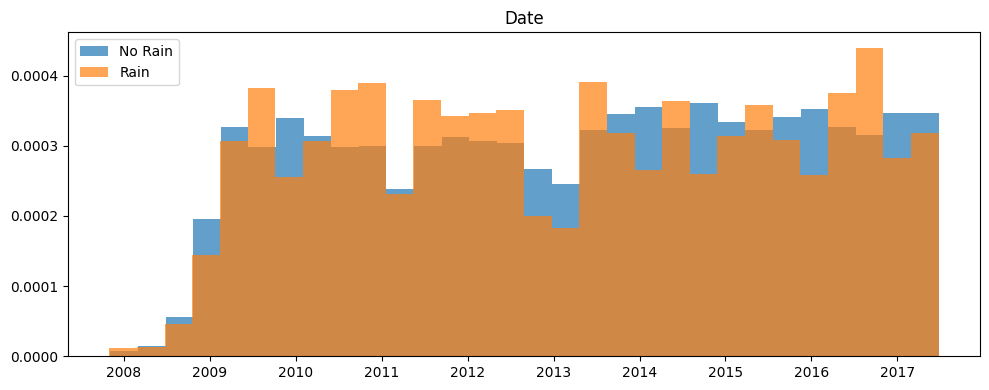

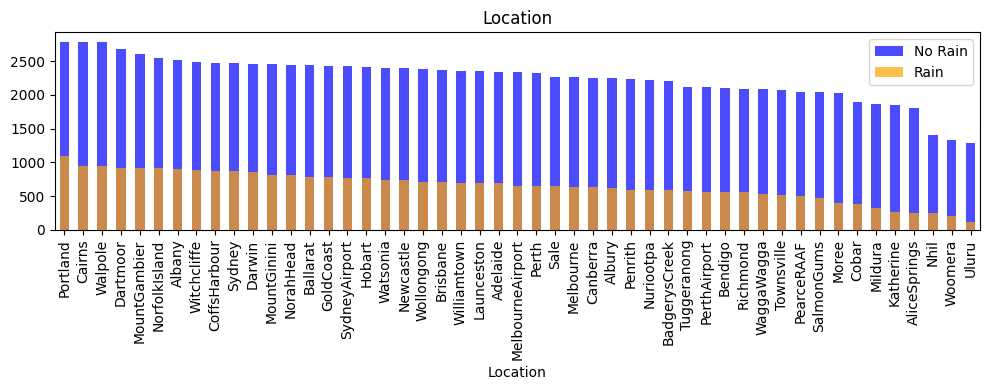

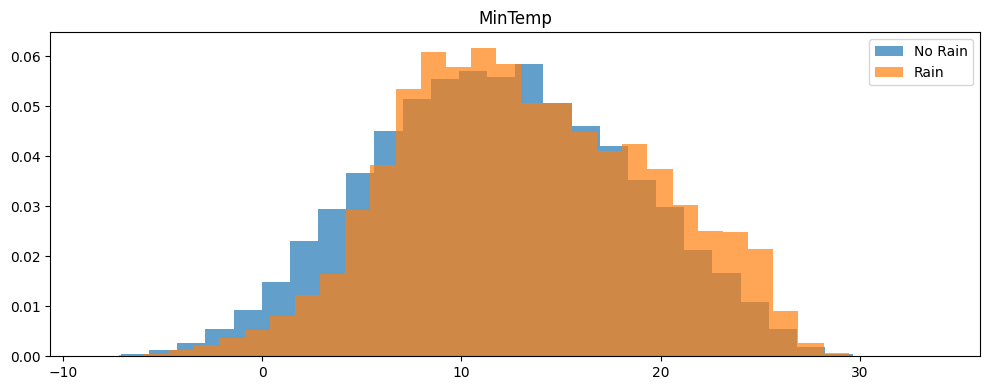

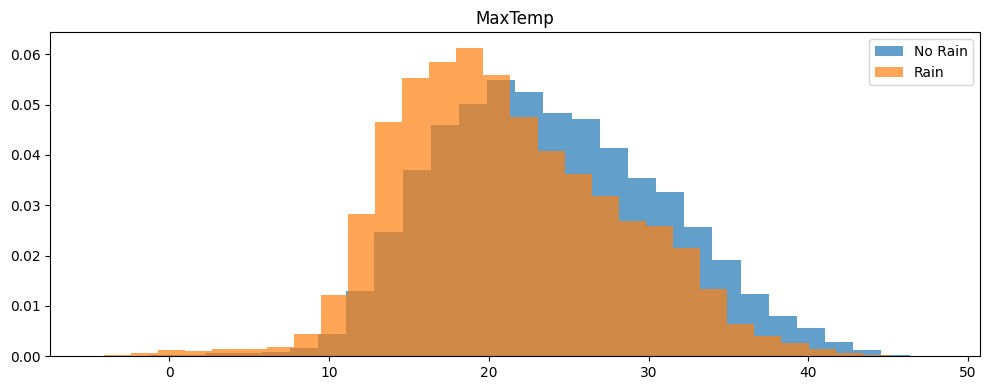

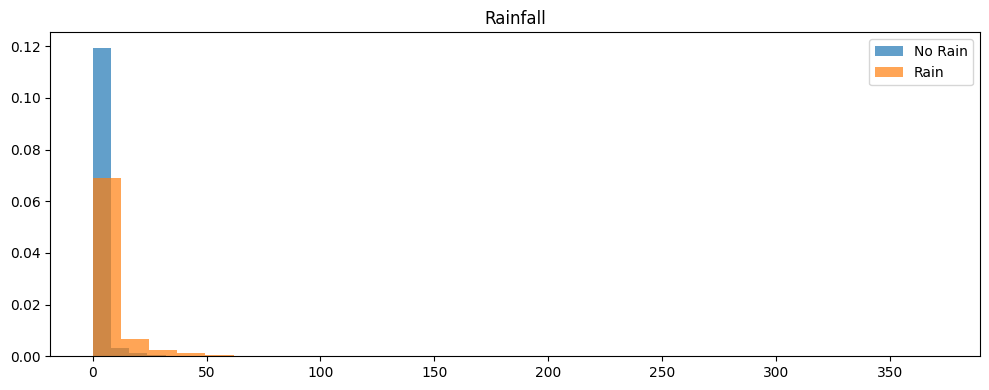

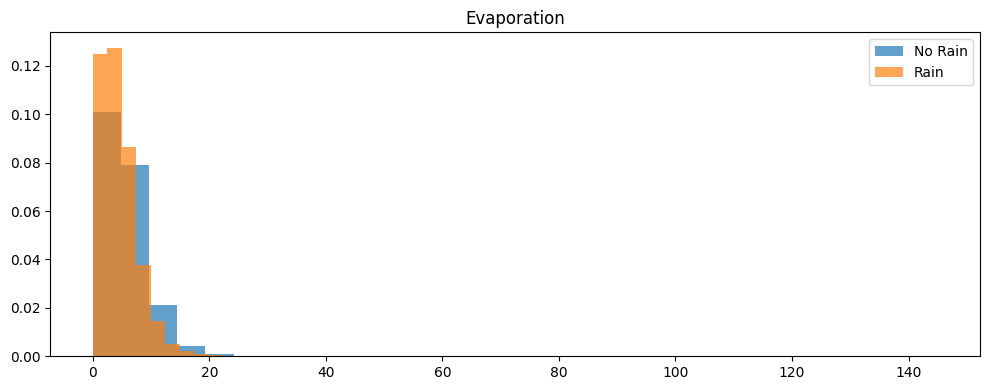

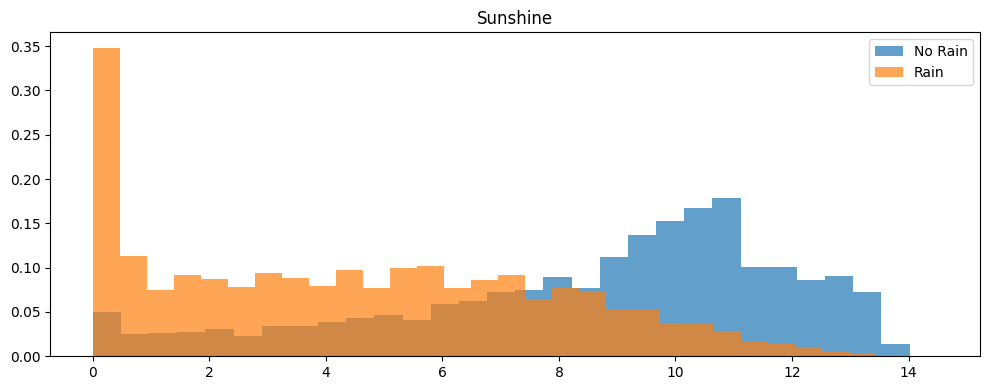

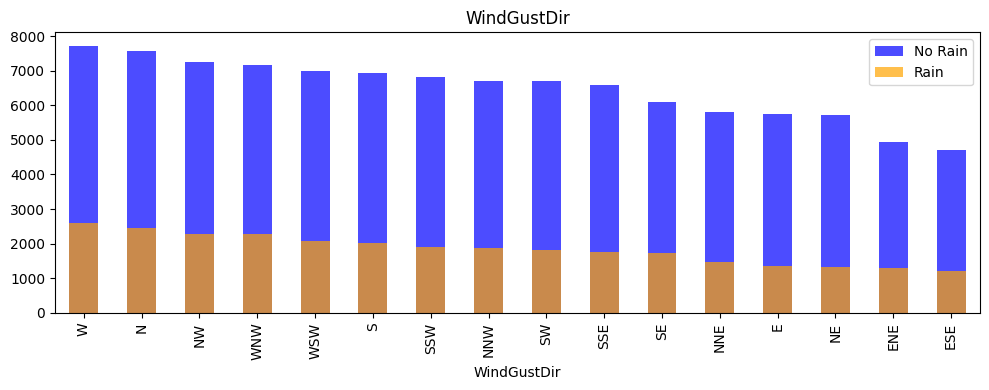

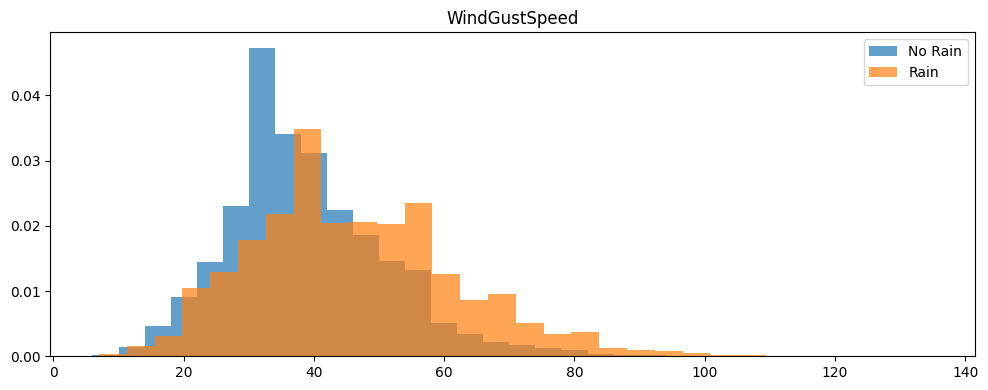

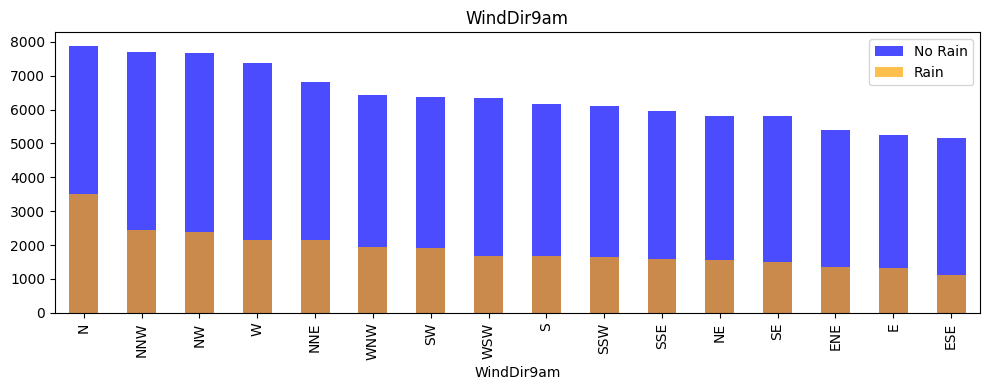

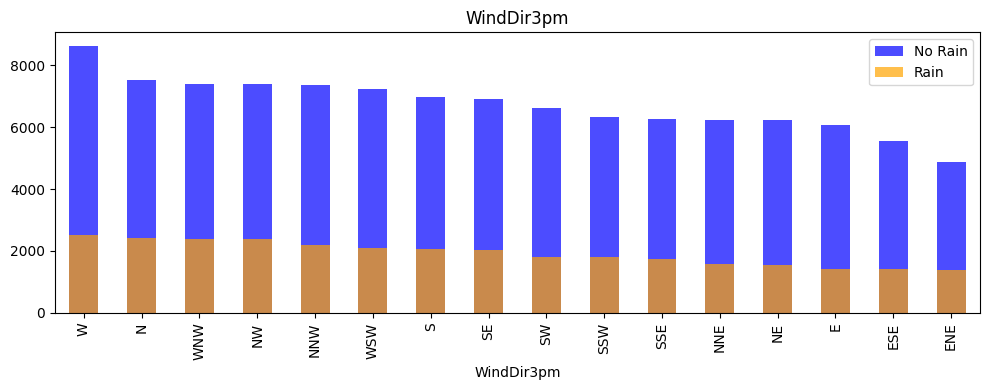

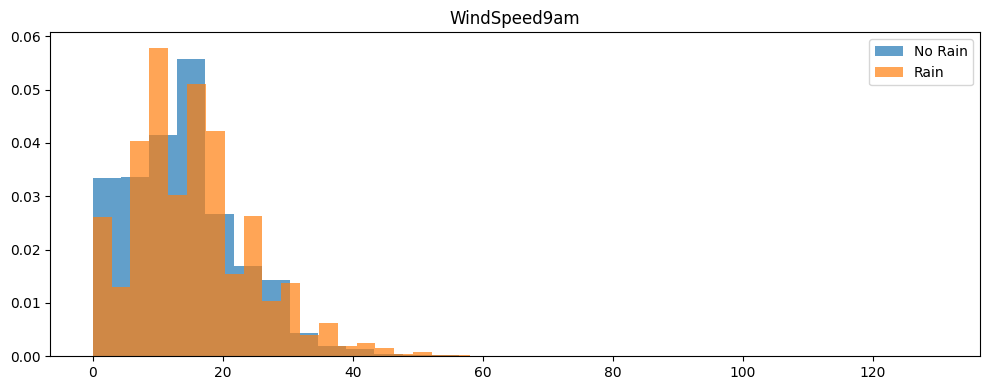

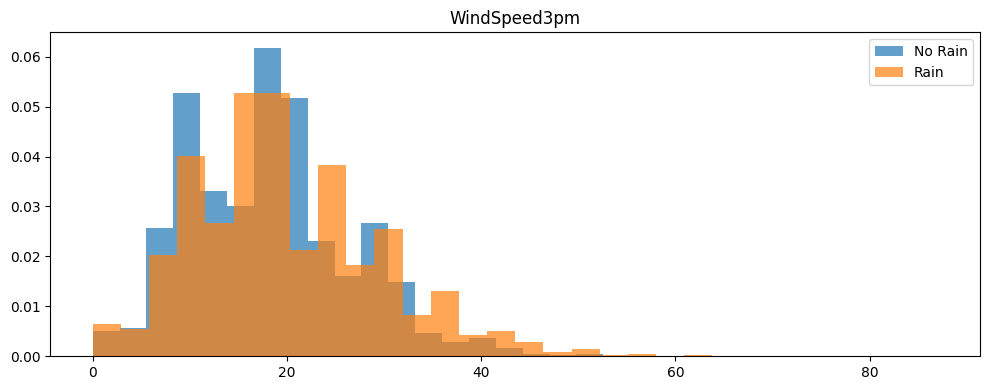

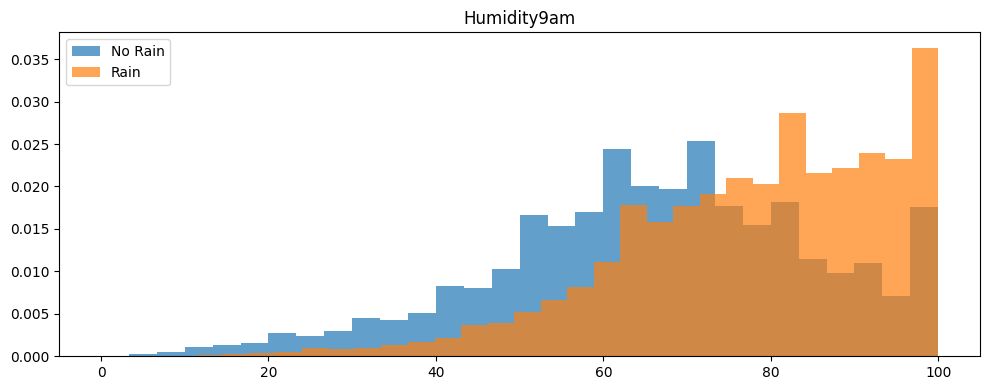

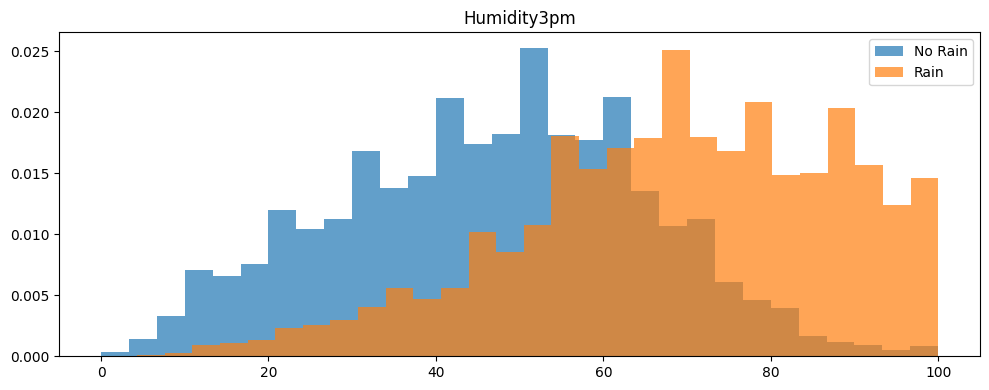

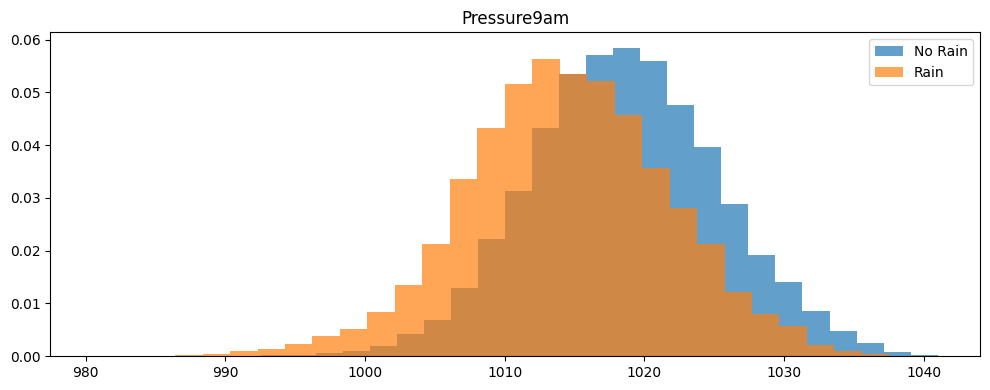

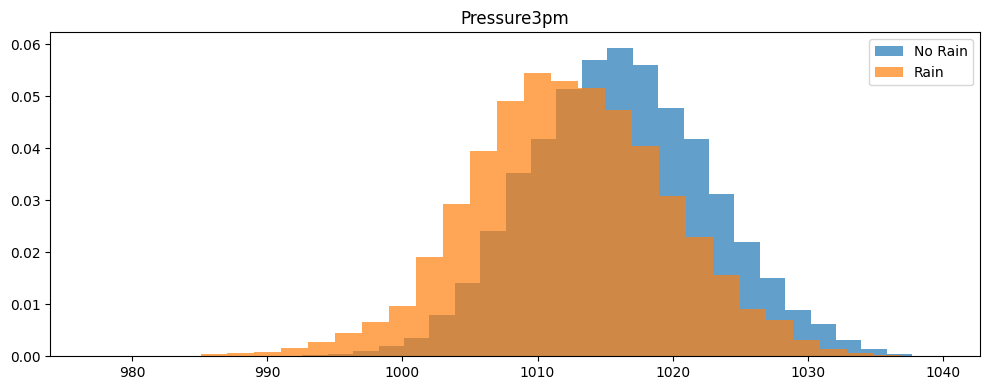

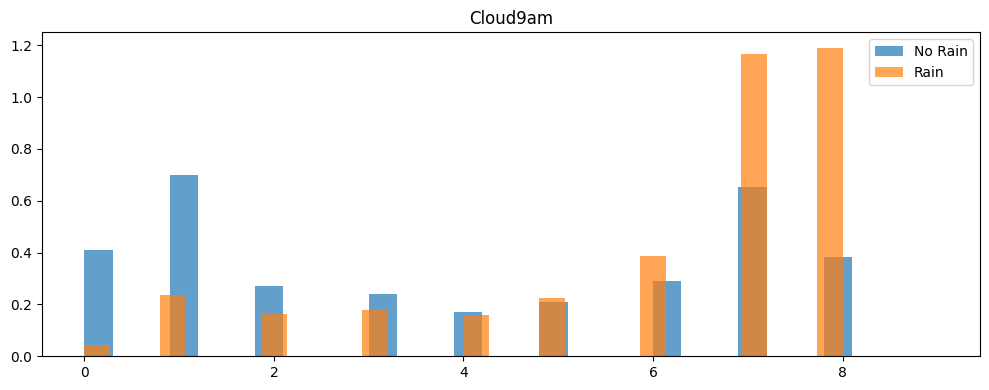

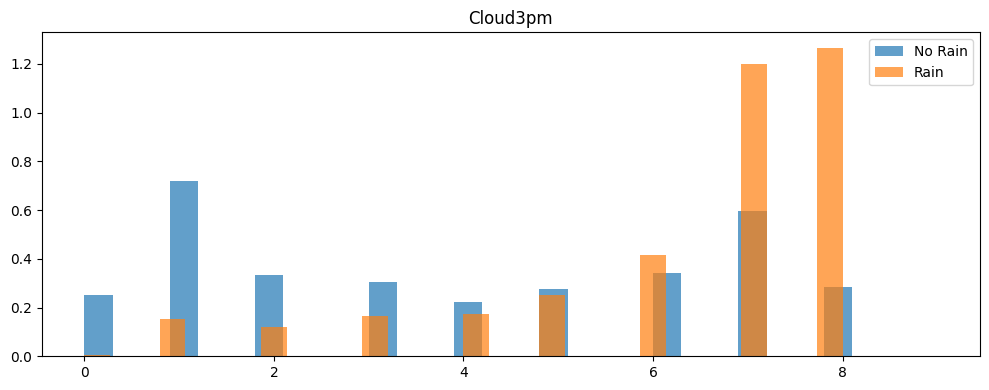

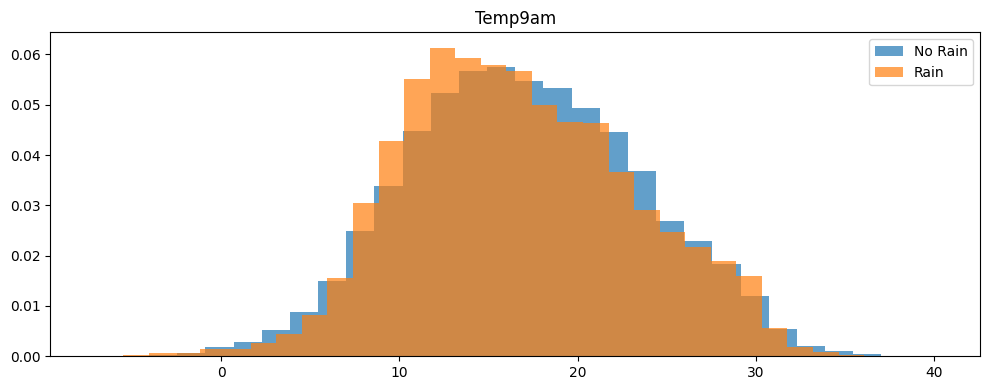

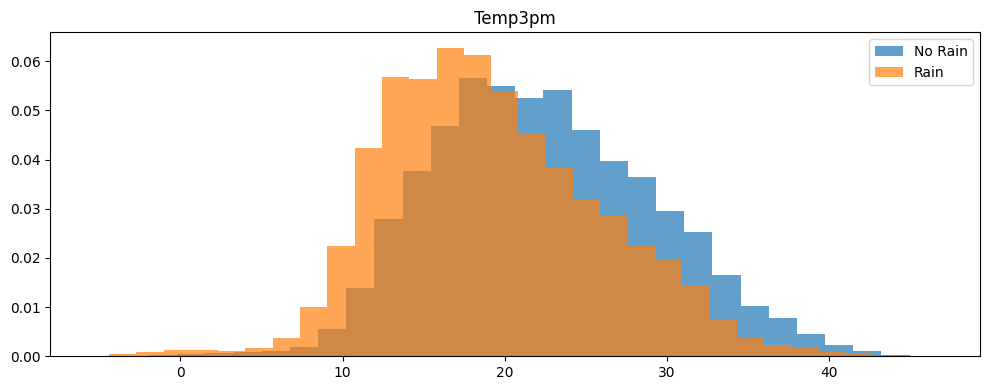

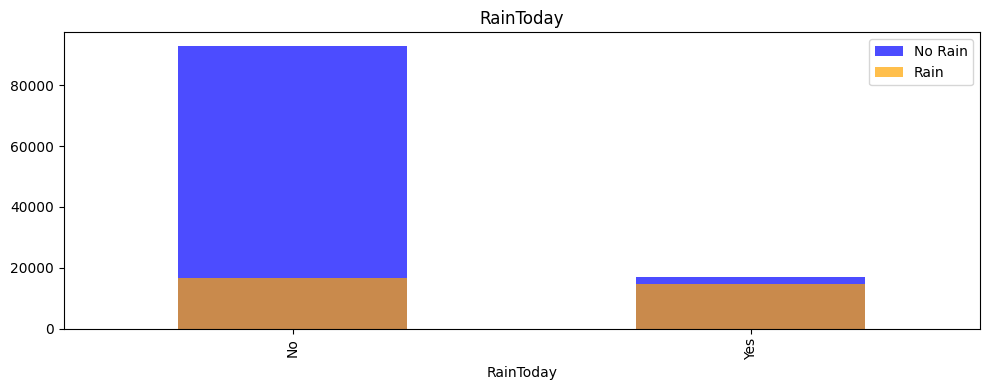

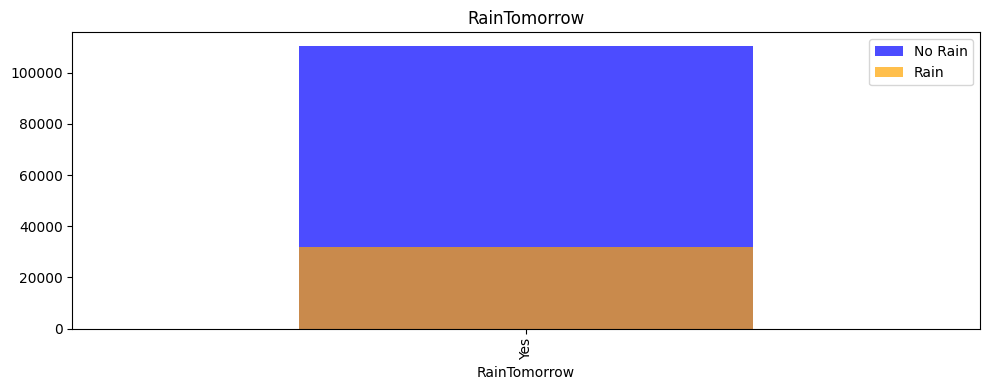

In [ ]:
for col in data.columns:
    if col in ['RainTomorrow', 'Date']:
        continue

    fig, ax = plt.subplots(figsize=(10, 4))

    cl0 = data.loc[data['RainTomorrow'] == 'No', col]
    cl1 = data.loc[data['RainTomorrow'] == 'Yes', col]

    if data[col].dtype == 'object':
        cl0.value_counts().plot(kind='bar', ax=ax, alpha=0.7, label='No Rain', color='blue')
        cl1.value_counts().plot(kind='bar', ax=ax, alpha=0.7, label='Rain', color='orange')
    else:
        ax.hist(cl0, bins=30, alpha=0.7, label='No Rain', density = True)
        ax.hist(cl1, bins=30, alpha=0.7, label='Rain', density = True)

    ax.legend()
    ax.set_title(col)
    plt.tight_layout()
    plt.show()

In [ ]:
numeric_features = (
    data
    .select_dtypes(include=['number'])
    .columns
    .tolist()
)
categorical_features = (
    data
    .select_dtypes(exclude=['number'])
    .columns
    .tolist()
)

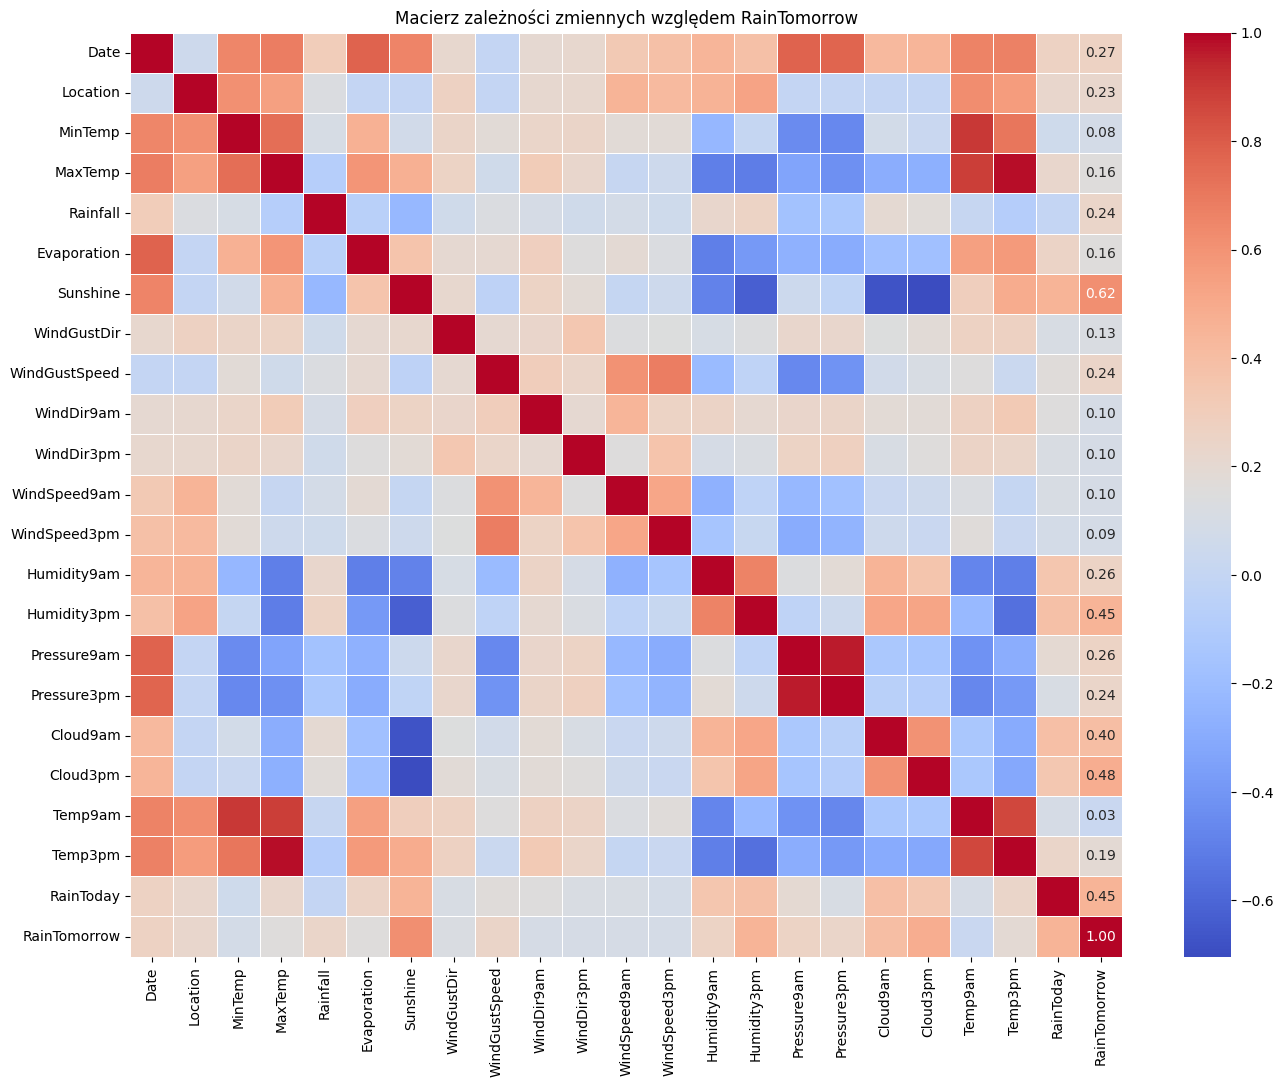

In [ ]:
def cramers_v(x, y):

    confusion_matrix = pd.crosstab(x, y)

    chi2 = chi2_contingency(confusion_matrix)[0]

    n = confusion_matrix.sum().sum()

    phi2 = chi2 / n

    r, k = confusion_matrix.shape

    return np.sqrt(phi2 / min(k - 1, r - 1))


def correlation_ratio(categories, measurements):

    categories = pd.Categorical(categories)

    cat_codes = categories.codes

    y_avg_array = np.zeros(len(categories.categories))

    n_array = np.zeros(len(categories.categories))

    for i in range(len(categories.categories)):

        cat_measures = measurements[cat_codes == i]

        n_array[i] = len(cat_measures)

        y_avg_array[i] = np.mean(cat_measures)

    y_total_avg = np.sum(y_avg_array * n_array) / np.sum(n_array)

    numerator = np.sum(
        n_array * (y_avg_array - y_total_avg) ** 2
    )

    denominator = np.sum(
        (measurements - y_total_avg) ** 2
    )

    if denominator == 0:
        return 0

    return np.sqrt(numerator / denominator)


df = data.copy()

for col in categorical_features:
    df[col] = df[col].fillna('BRAK')

all_cols = df.columns

corr_matrix = pd.DataFrame(
    np.zeros((len(all_cols), len(all_cols))),
    index=all_cols,
    columns=all_cols
)

for col1 in all_cols:

    for col2 in all_cols:

        if (
            pd.api.types.is_numeric_dtype(df[col1]) and
            pd.api.types.is_numeric_dtype(df[col2])
        ):

            corr = df[col1].corr(df[col2])

        elif (
            not pd.api.types.is_numeric_dtype(df[col1]) and
            not pd.api.types.is_numeric_dtype(df[col2])
        ):

            corr = cramers_v(df[col1], df[col2])

        else:

            if pd.api.types.is_numeric_dtype(df[col1]):

                corr = correlation_ratio(
                    df[col2],
                    df[col1]
                )

            else:

                corr = correlation_ratio(
                    df[col1],
                    df[col2]
                )

        corr_matrix.loc[col1, col2] = corr

annot_matrix = pd.DataFrame(
    "",
    index=corr_matrix.index,
    columns=corr_matrix.columns
)

for idx in annot_matrix.index:

    annot_matrix.loc[idx, 'RainTomorrow'] = (
        f"{corr_matrix.loc[idx, 'RainTomorrow']:.2f}"
    )

plt.figure(figsize=(16,12))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    annot=annot_matrix,
    fmt='',
    linewidths=0.5
)

plt.title(
    'Macierz zależności zmiennych względem RainTomorrow'
)

plt.show()

Z histogramów względem klas można odczytać jak mocno dana cecha wpływa na zmienną docelową.
Cechy które wpływają silnie: Location, Rainfall, Sunshine, Humidity9am, Humidity3pm, Pressure9am, Pressure3pm, Cloud9am, Cloud3pm, RainToday.
Cechy które wpływają średnio: MaxTemp, WindGustSpeed.
Słabe cechy: MinTemp, Evaporation, WindGustDir, WindDir9am, WindDir3pm, WindSpeed9am, WindSpeed3pm, Temp9am, Temp3pm. Macierz zależności potwierdziła wcześniejszą analizę wpływu cech, dlatego słabe cechy zdecydowano się usunąć, do późniejszych analiz.

## 3. Wspólne przygotowanie danych dla wszystkich modeli

In [ ]:
data_clean = data.dropna(
    subset=['RainTomorrow']
).copy()


prepared_df = data_clean.copy()

prepared_df['RainTomorrow'] = (
    prepared_df['RainTomorrow']
    .map({'No': 0, 'Yes': 1})
)

prepared_df['RainToday'] = (
    prepared_df['RainToday']
    .map({'No': 0, 'Yes': 1})
)


prepared_df['Date'] = pd.to_datetime(
    prepared_df['Date']
)

prepared_df['Year'] = prepared_df['Date'].dt.year
prepared_df['Month'] = prepared_df['Date'].dt.month
prepared_df['Day'] = prepared_df['Date'].dt.day

prepared_df = prepared_df.drop(columns=['Date'])
data_fs = prepared_df.copy()

prepared_df = prepared_df.drop(columns=[
    'WindGustDir',
    'WindDir9am',
    'WindDir3pm',
    'WindSpeed9am',
    'WindSpeed3pm',
    'Location',
    'MinTemp',
    'MaxTemp',
    'Evaporation',
    'Temp9am',
])


complete_cases = prepared_df.dropna().copy()

test_df = complete_cases.sample(
    frac=0.8,
    random_state=0
)

train_df = prepared_df.drop(test_df.index)

X_train_missing = train_df.drop(
    columns=['RainTomorrow']
)

y_train_missing = train_df['RainTomorrow']

X_test_complete = test_df.drop(
    columns=['RainTomorrow']
)

y_test_complete = test_df['RainTomorrow']


numeric_features = (
    X_train_missing
    .select_dtypes(include=['number'])
    .columns
    .tolist()
)

categorical_features = (
    X_train_missing
    .select_dtypes(exclude=['number'])
    .columns
    .tolist()
)

print(f'Train shape: {X_train_missing.shape}')
print(f'Test shape: {X_test_complete.shape}')

print(f'Liczba cech numerycznych: {len(numeric_features)}')
print(f'Liczba cech kategorycznych: {len(categorical_features)}')

Train shape: (94140, 14)
Test shape: (48053, 14)
Liczba cech numerycznych: 14
Liczba cech kategorycznych: 0


In [ ]:
y_test_complete

,RainTomorrow
105592,0
86857,0
71501,0
99964,0
137655,0
...,...
34811,0
93471,0
141783,0
137586,0


In [ ]:
total_rows = len(prepared_df)
train_rows = len(train_df)
test_rows = len(test_df)

print(f'Liczba wszystkich wierszy: {total_rows}')
print(f'Train: {train_rows / total_rows:.2%}')
print(f'Test: {test_rows / total_rows:.2%}')

train_missing = train_df.isna().sum().sum()
test_complete = test_df.isna().sum().sum()

print(f'Liczba braków w train set: {train_missing}')
print(f'Liczba braków w test set: {test_complete}')

Liczba wszystkich wierszy: 142193
Train: 66.21%
Test: 33.79%
Liczba braków w train set: 226754
Liczba braków w test set: 0


In [ ]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    end = time.perf_counter()
    y_pred = model.predict(X_test)
    return {
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 3),
        'Precision': round(precision_score(y_test, y_pred), 3),
        'Recall': round(recall_score(y_test, y_pred), 3),
        'F1': round(f1_score(y_test, y_pred), 3),
        'Confusion matrix': confusion_matrix(y_test, y_pred),
        'Time': round(end - start, 4)
    }


## 4. Przypadek bazowy (1) - usunięcie wszystkich rekordów z brakami


In [ ]:

dane_przypadek_bazowy_train = pd.concat([X_train_missing, y_train_missing], axis=1).dropna().copy()
dane_przypadek_bazowy_test = pd.concat([X_test_complete, y_test_complete], axis=1).copy()

print(f'Rozmiar przypadku bazowego train: {dane_przypadek_bazowy_train.shape}')
print(f'Rozmiar przypadku bazowego test: {dane_przypadek_bazowy_test.shape}')


Rozmiar przypadku bazowego train: (12013, 15)
Rozmiar przypadku bazowego test: (48053, 15)


In [ ]:
start = time.perf_counter()
baseline_complete_cases = X_train_missing.dropna().index

X_train_baseline = X_train_missing.loc[baseline_complete_cases].copy()

y_train_baseline = y_train_missing.loc[baseline_complete_cases].copy()


X_test_baseline = X_test_complete.copy()
y_test_baseline = y_test_complete.copy()

scaler = StandardScaler()

X_train_baseline_scaled = scaler.fit_transform(X_train_baseline)
X_test_baseline_scaled = scaler.transform(X_test_baseline)

end = time.perf_counter()
baseline_time = end - start

print(
    f'Czas wykonania Baseline: '
    f'{baseline_time:.4f} s'
)


Czas wykonania Baseline: 0.0264 s


## 5. Modelowanie i ocena przypadku bazowego 1


In [ ]:
baseline_results = []

# Decision Tree
baseline_results.append(
    evaluate_model(
        'Decision Tree - Baseline',
        DecisionTreeClassifier(random_state=0),
        X_train_baseline,
        y_train_baseline,
        X_test_baseline,
        y_test_baseline
    )
)

# SVM
baseline_results.append(
    evaluate_model(
        'SVM - Baseline',
        SVC(kernel='rbf'),
        X_train_baseline_scaled,
        y_train_baseline,
        X_test_baseline_scaled,
        y_test_baseline
    )
)

# Random Forest
baseline_results.append(
    evaluate_model(
        'Random Forest - Baseline',
        RandomForestClassifier(random_state=0),
        X_train_baseline,
        y_train_baseline,
        X_test_baseline,
        y_test_baseline
    )
)


results_baseline_df = pd.DataFrame(baseline_results)

display(results_baseline_df)

,Model,Accuracy,Precision,Recall,F1,Confusion matrix,Time
0,Decision Tree - Baseline,0.791,0.528,0.561,0.544,"[[32058, 5346], [4679, 5970]]",0.1258
1,SVM - Baseline,0.854,0.757,0.501,0.603,"[[35691, 1713], [5311, 5338]]",3.7619
2,Random Forest - Baseline,0.854,0.742,0.526,0.616,"[[35452, 1952], [5044, 5605]]",2.3102


## 6. Simple Imputer

In [ ]:
#SimpleImputer
start = time.perf_counter()

X_train_SimpleImputer = X_train_missing.copy()
X_test_SimpleImputer = X_test_complete.copy()

imputer_num = SimpleImputer(missing_values = np.nan, strategy ='median')

imputer_num_fitted = imputer_num.fit(X_train_missing[numeric_features])
X_train_SimpleImputer[numeric_features] = imputer_num_fitted.transform(X_train_missing[numeric_features])

scaler = StandardScaler()

X_train_SimpleImputer_scaled = scaler.fit_transform(X_train_SimpleImputer)
X_test_SimpleImputer_scaled = scaler.transform(X_test_SimpleImputer)

end = time.perf_counter()
simple_imputer_time = end - start

print(
    f'Czas wykonania Simple Imputer: '
    f'{simple_imputer_time:.4f} s'
)

Czas wykonania Simple Imputer: 0.2054 s


In [ ]:
simple_results = []

# Decision Tree

simple_results.append(
    evaluate_model(
        'Decision Tree - Simple Imputer',
        DecisionTreeClassifier(random_state=0),
        X_train_SimpleImputer,
        y_train_missing,
        X_test_SimpleImputer,
        y_test_complete
    )
)

# SVM

simple_results.append(
    evaluate_model(
        'SVM - Simple Imputer',
        SVC(random_state=0),
        X_train_SimpleImputer_scaled,
        y_train_missing,
        X_test_SimpleImputer_scaled,
        y_test_complete
    )
)

# Random Forest
simple_results.append(
    evaluate_model(
        'Random Forest - Simple Imputer',
        RandomForestClassifier(
            n_estimators=100,
            random_state=0
        ),
        X_train_SimpleImputer,
        y_train_missing,
        X_test_SimpleImputer,
        y_test_complete
    )
)


simple_results_df = pd.DataFrame(simple_results)

display(simple_results_df)

,Model,Accuracy,Precision,Recall,F1,Confusion matrix,Time
0,Decision Tree - Simple Imputer,0.780,0.502,0.548,0.524,"[[31623, 5781], [4814, 5835]]",1.4631
1,SVM - Simple Imputer,0.854,0.752,0.510,0.608,"[[35608, 1796], [5213, 5436]]",394.8021
2,Random Forest - Simple Imputer,0.857,0.750,0.533,0.623,"[[35515, 1889], [4973, 5676]]",20.6446


# 7. Iterative Imputer

In [ ]:
#IterativeImputer
start = time.perf_counter()

X_train_IterativeImputer = X_train_missing.copy()
X_test_IterativeImputer = X_test_complete.copy()

# Iterative Imputer
iterative_imputer = IterativeImputer(
    random_state=0,
    max_iter=15
)

iterative_imputer_fitted = iterative_imputer.fit(X_train_missing)

X_train_IterativeImputer[:] = (iterative_imputer_fitted.transform(X_train_missing))

scaler = StandardScaler()

X_train_IterativeImputer_scaled = scaler.fit_transform(X_train_IterativeImputer)
X_test_IterativeImputer_scaled = scaler.transform(X_test_IterativeImputer)

end = time.perf_counter()
iterative_imputer_time = end - start

print(
    f'Czas wykonania Iterative Imputer: '
    f'{iterative_imputer_time:.4f} s'
)

Czas wykonania Iterative Imputer: 23.8093 s


In [ ]:
iterative_results = []

#Decision Tree

iterative_results.append(
    evaluate_model(
        'Decision Tree - Iterative Imputer',
        DecisionTreeClassifier(random_state=0),
        X_train_IterativeImputer,
        y_train_missing,
        X_test_IterativeImputer,
        y_test_complete
    )
)

#SVM

iterative_results.append(
    evaluate_model(
        'SVM - Iterative Imputer',
        SVC(random_state=0),
        X_train_IterativeImputer_scaled,
        y_train_missing,
        X_test_IterativeImputer_scaled,
        y_test_complete
    )
)

#Random Forest
iterative_results.append(
    evaluate_model(
        'Random Forest - Iterative Imputer',
        RandomForestClassifier(
            n_estimators=100,
            random_state=0
        ),
        X_train_IterativeImputer,
        y_train_missing,
        X_test_IterativeImputer,
        y_test_complete
    )
)
iterative_results_df = pd.DataFrame(iterative_results)
display(iterative_results_df)

,Model,Accuracy,Precision,Recall,F1,Confusion matrix,Time
0,Decision Tree - Iterative Imputer,0.788,0.521,0.531,0.526,"[[32213, 5191], [4998, 5651]]",1.9174
1,SVM - Iterative Imputer,0.851,0.792,0.448,0.572,"[[36150, 1254], [5883, 4766]]",367.7604
2,Random Forest - Iterative Imputer,0.856,0.772,0.497,0.605,"[[35837, 1567], [5356, 5293]]",30.5981


#8. KNN Imputer

In [ ]:
start = time.perf_counter()

X_train_KNNImputer = X_train_missing.copy()
X_test_KNNImputer = X_test_complete.copy()

scaler = StandardScaler()

X_train_KNN_scaled = scaler.fit_transform(X_train_KNNImputer)
X_test_KNN_scaled = scaler.transform(X_test_KNNImputer)

# KNN Imputer
knn_imputer = KNNImputer(
    n_neighbors=4
)

knn_imputer_fitted = knn_imputer.fit(X_train_KNN_scaled)
X_train_KNNImputer = knn_imputer_fitted.transform(X_train_KNN_scaled)

X_test_KNNImputer = X_test_KNN_scaled.copy()

end = time.perf_counter()
knn_imputer_time = end - start

print(
    f'Czas wykonania KNN Imputer: '
    f'{knn_imputer_time:.4f} s'
)

Czas wykonania KNN Imputer: 625.0650 s


In [ ]:
KNN_results = []

# Decision Tree
KNN_results.append(
    evaluate_model(
        'Decision Tree - KNN Imputer',
        DecisionTreeClassifier(random_state=0),
        X_train_KNNImputer,
        y_train_missing,
        X_test_KNNImputer,
        y_test_complete
    )
)

# SVM
KNN_results.append(
    evaluate_model(
        'SVM - KNN Imputer',
        SVC(random_state=0),
        X_train_KNNImputer,
        y_train_missing,
        X_test_KNNImputer,
        y_test_complete
    )
)

# Random Forest
KNN_results.append(
    evaluate_model(
        'Random Forest - KNN Imputer',
        RandomForestClassifier(
            n_estimators=100,
            random_state=0
        ),
        X_train_KNNImputer,
        y_train_missing,
        X_test_KNNImputer,
        y_test_complete
    )
)


KNN_results_df = pd.DataFrame(KNN_results)

display(KNN_results_df)

,Model,Accuracy,Precision,Recall,F1,Confusion matrix,Time
0,Decision Tree - KNN Imputer,0.780,0.503,0.532,0.517,"[[31801, 5603], [4980, 5669]]",1.3078
1,SVM - KNN Imputer,0.852,0.793,0.451,0.575,"[[36151, 1253], [5851, 4798]]",370.0299
2,Random Forest - KNN Imputer,0.855,0.766,0.496,0.602,"[[35791, 1613], [5368, 5281]]",23.3285


# 9. Porównanie modeli

In [ ]:
all_results = pd.concat(
    [
        results_baseline_df,
        simple_results_df,
        iterative_results_df,
        KNN_results_df
    ],
    ignore_index=True
)

all_results = all_results.sort_values(
    by='F1',
    ascending=False
)

display(
    all_results.drop(columns=['Confusion matrix'])
)

,Model,Accuracy,Precision,Recall,F1,Time
5,Random Forest - Simple Imputer,0.857,0.750,0.533,0.623,20.6446
2,Random Forest - Baseline,0.854,0.742,0.526,0.616,2.3102
4,SVM - Simple Imputer,0.854,0.752,0.510,0.608,394.8021
8,Random Forest - Iterative Imputer,0.856,0.772,0.497,0.605,30.5981
1,SVM - Baseline,0.854,0.757,0.501,0.603,3.7619
11,Random Forest - KNN Imputer,0.855,0.766,0.496,0.602,23.3285
10,SVM - KNN Imputer,0.852,0.793,0.451,0.575,370.0299
7,SVM - Iterative Imputer,0.851,0.792,0.448,0.572,367.7604
0,Decision Tree - Baseline,0.791,0.528,0.561,0.544,0.1258
6,Decision Tree - Iterative Imputer,0.788,0.521,0.531,0.526,1.9174


Ze względu na nierównoważność klas ostateczne modele porównywano względem miary F1 score. Model, który przewiduje tylko dni bezdeszczowe nadal może mieć wysokie accuracy. Dlatego jako główną metrykę oceny wybrano miarę F1, będącą harmoniczną średnią precyzji i czułości. Miara ta penalizuje jednocześnie fałszywe alarmy (FP) i przeoczone przypadki deszczu (FN), wymuszając kompromis między nimi, co jest pożądane w zadaniach klasyfikacji binarnej przy niezbalansowanych danych. Najlepszy wynik udało się osiągnąć dla Random Forest w połączeniu z Simple Imputer.

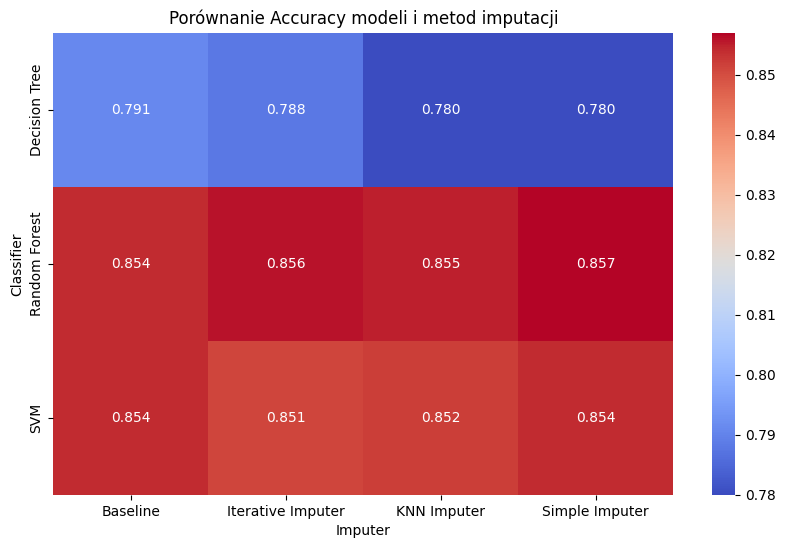

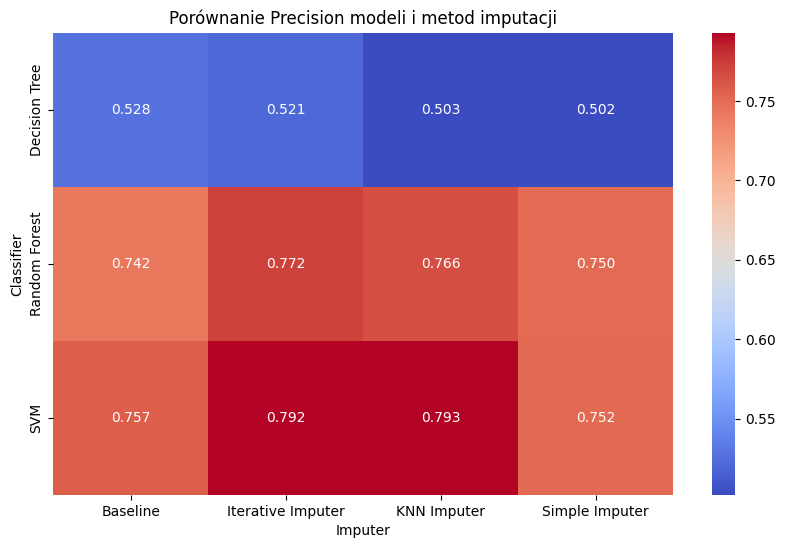

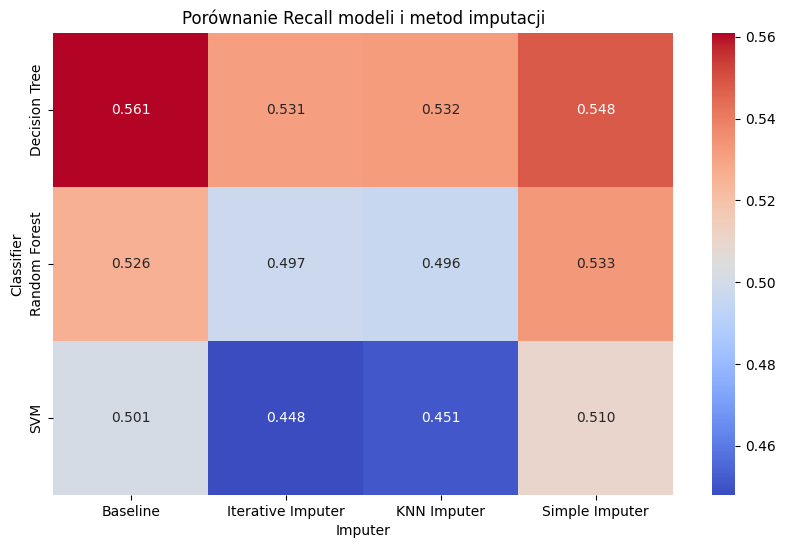

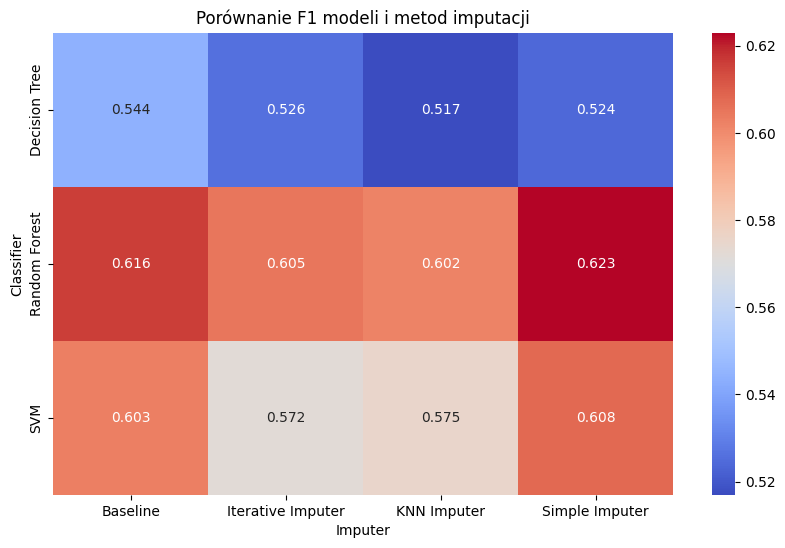

In [ ]:
heatmap_df = all_results.copy()

heatmap_df['Classifier'] = heatmap_df['Model']
heatmap_df['Imputer'] = 'Baseline'

mask = heatmap_df['Model'].str.contains(' - ')

heatmap_df.loc[mask, ['Classifier', 'Imputer']] = (
    heatmap_df.loc[mask, 'Model']
    .str.split(' - ', n=1, expand=True)
    .values
)

heatmap_df['Classifier'] = (
    heatmap_df['Classifier']
    .str.replace(r'\s*\(scaled\)', '', regex=True)
    .str.strip()
)

metrics = ['Accuracy', 'Precision', 'Recall', 'F1']

for metric in metrics:

    pivot_metric = heatmap_df.pivot_table(
        values=metric,
        index='Classifier',
        columns='Imputer'
    )

    plt.figure(figsize=(10,6))

    sns.heatmap(
        pivot_metric,
        annot=True,
        cmap='coolwarm',
        fmt=".3f"
    )

    plt.title(f'Porównanie {metric} modeli i metod imputacji')

    plt.show()

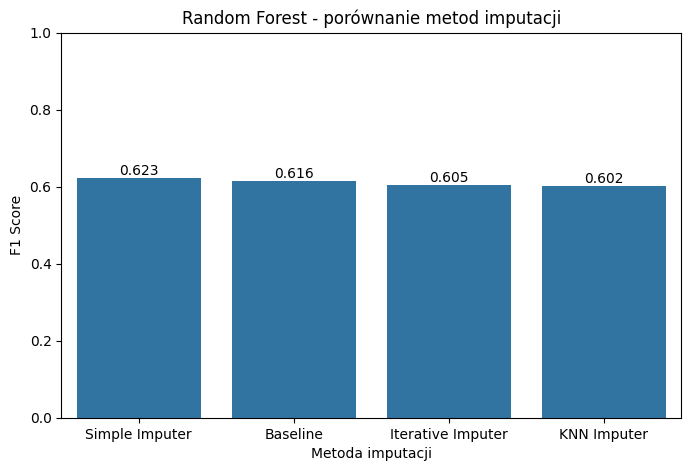

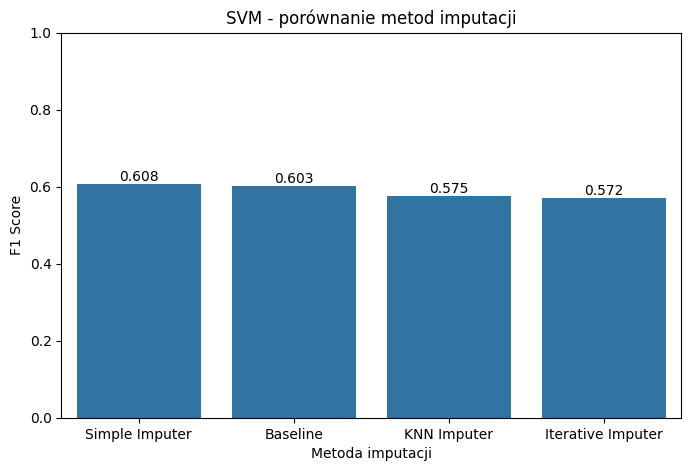

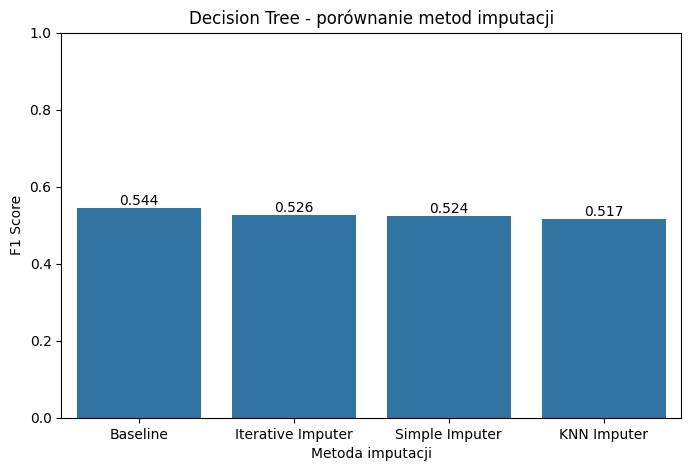

In [ ]:
for model_name in heatmap_df['Classifier'].unique():

    model_df = heatmap_df[
        heatmap_df['Classifier'] == model_name
    ]

    plt.figure(figsize=(8,5))

    ax = sns.barplot(
        data=model_df,
        x='Imputer',
        y='F1'
    )

    # wartości nad słupkami
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f')

    plt.ylim(0, 1)

    plt.title(
        f'{model_name} - porównanie metod imputacji'
    )

    plt.ylabel('F1 Score')

    plt.xlabel('Metoda imputacji')

    plt.show()

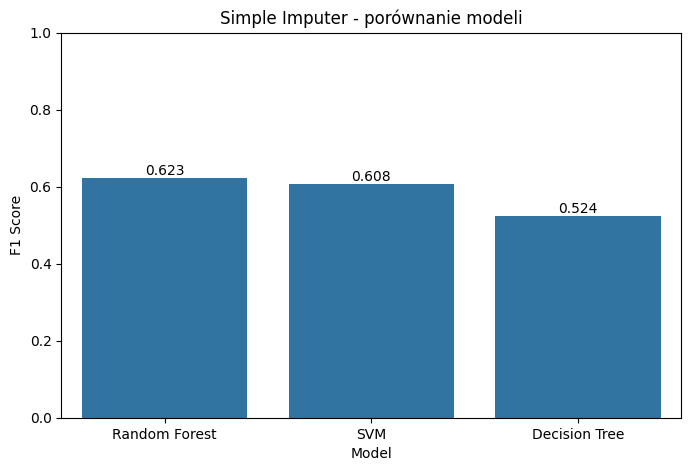

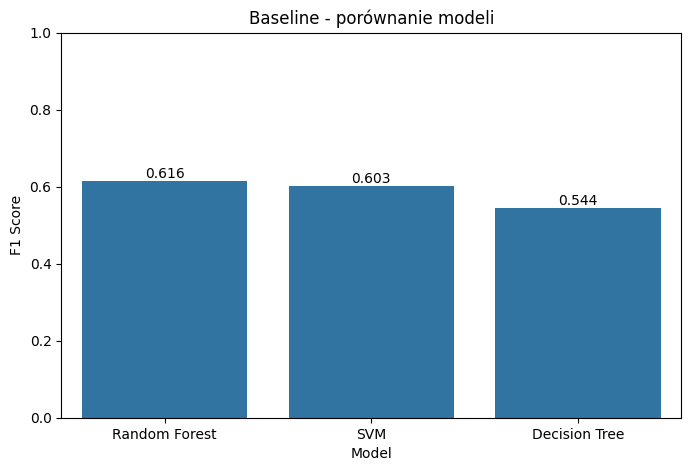

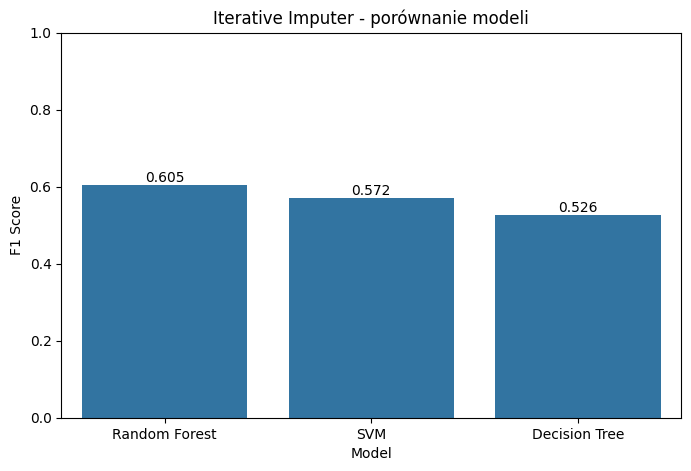

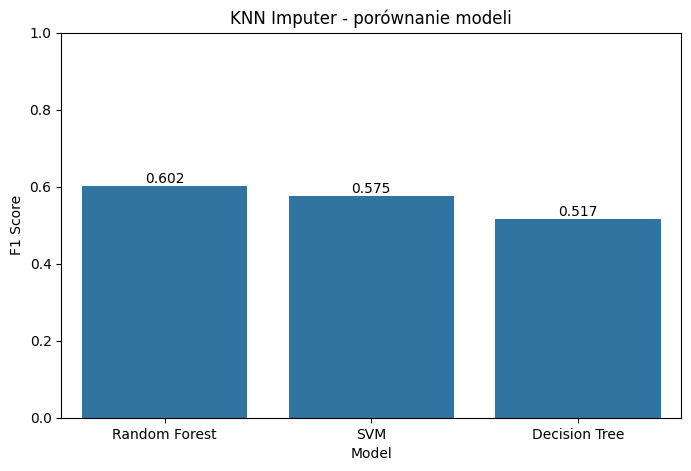

In [ ]:
plot_df = all_results.copy()

plot_df['Classifier'] = plot_df['Model']
plot_df['Imputer'] = 'Baseline'

mask = plot_df['Model'].str.contains(' - ')

plot_df.loc[mask, ['Classifier', 'Imputer']] = (
    plot_df.loc[mask, 'Model']
    .str.split(' - ', n=1, expand=True)
    .values
)

plot_df['Classifier'] = (
    plot_df['Classifier']
    .str.replace(r'\s*\(scaled\)', '', regex=True)
    .str.strip()
)

imputers = plot_df['Imputer'].unique()

for imputer_name in imputers:

    imputer_df = plot_df[
        plot_df['Imputer'] == imputer_name
    ]

    plt.figure(figsize=(8,5))

    ax = sns.barplot(
        data=imputer_df,
        x='Classifier',
        y='F1'
    )

    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f')

    plt.ylim(0, 1)

    plt.title(
        f'{imputer_name} - porównanie modeli'
    )

    plt.ylabel('F1 Score')

    plt.xlabel('Model')

    plt.show()

## Wykresy podsumowujące

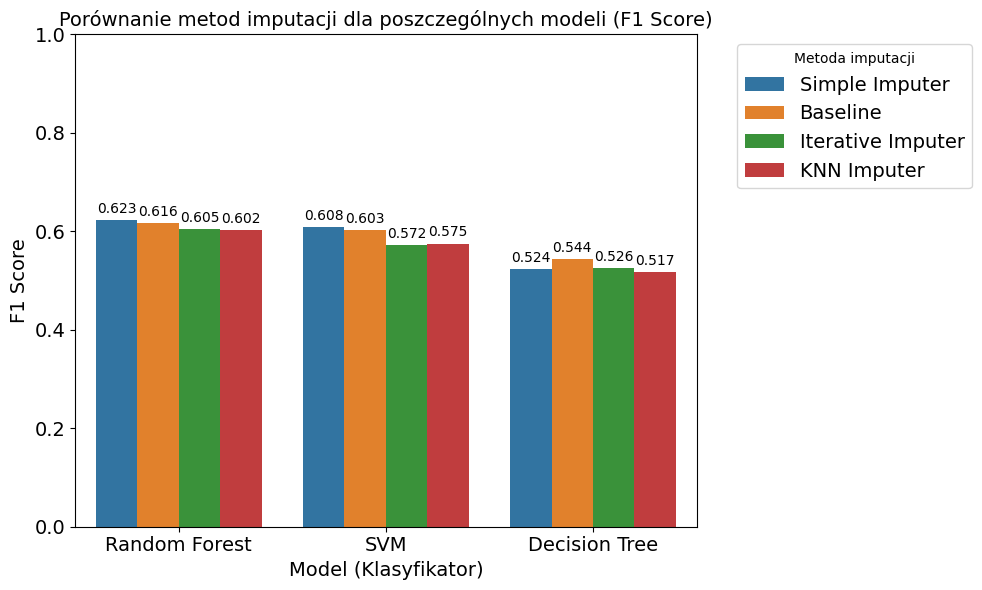

In [ ]:
df_plot = all_results.drop(columns=['Confusion matrix']).copy()

df_plot[['Classifier', 'Imputer']] = df_plot['Model'].str.split(' - ', expand=True)

plt.figure(figsize=(10, 6))

ax1 = sns.barplot(
    data=df_plot,
    x='Classifier',
    y='F1',
    hue='Imputer'
)

for container in ax1.containers:
    ax1.bar_label(container, fmt='%.3f', padding=3, fontsize=10)

plt.ylim(0, 1)
plt.title('Porównanie metod imputacji dla poszczególnych modeli (F1 Score)', fontsize=14)
plt.ylabel('F1 Score', fontsize=14)
plt.xlabel('Model (Klasyfikator)', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(title='Metoda imputacji', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=14)
plt.tight_layout()
plt.show()

Z wykresu można zauważyć, że we wszystkich trzech modelach różnice między metodami imputacji były niewielkie. rozstęp wyników w obrębie jednego klasyfikatora nie przekraczał 0.032 punktu. Sugeruje to, że wybór metody imputacji miał ograniczony wpływ na jakość predykcji. Spośród metod imputacji, Simple Imputer najczęściej dawał wyniki równe bądź nieznacznie lepsze od pozostałych, przy czym w przypadku Decision Tree nieznaczną przewagę uzyskał Baseline. Metody bardziej zaawansowane, czyli KNN Imputer oraz Iterative Imputer, nie przyniosły poprawy względem prostszych podejść, co może wskazywać, że złożoność procesu imputacji nie rekompensuje wprowadzanego przez nie szumu.

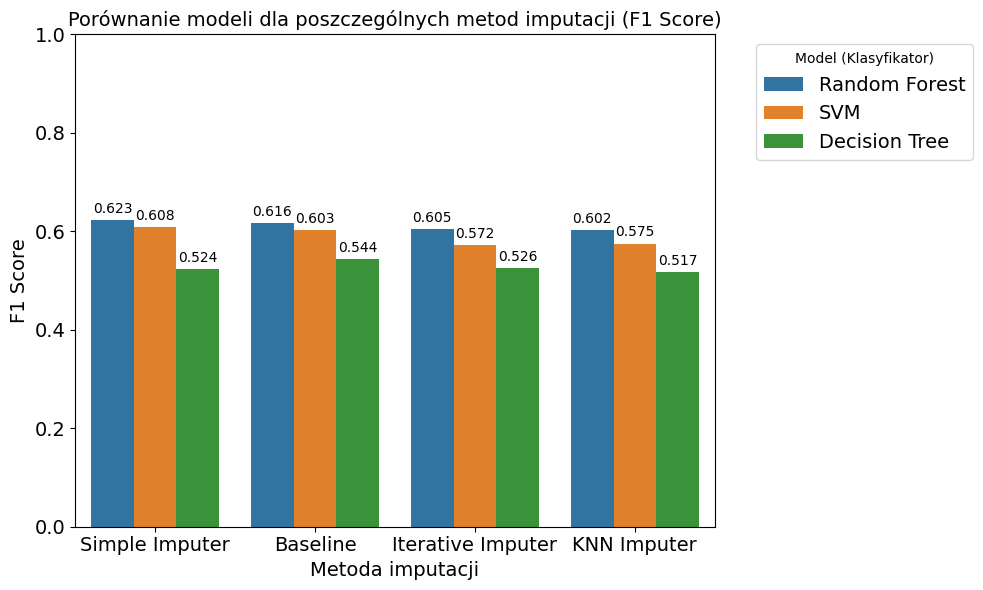

In [ ]:
df_plot = all_results.drop(columns=['Confusion matrix']).copy()

df_plot[['Classifier', 'Imputer']] = df_plot['Model'].str.split(' - ', expand=True)
plt.figure(figsize=(10, 6))

ax2 = sns.barplot(
    data=df_plot,
    x='Imputer',
    y='F1',
    hue='Classifier'
)

for container in ax2.containers:
    ax2.bar_label(container, fmt='%.3f', padding=3, fontsize=10)

plt.ylim(0, 1)
plt.title('Porównanie modeli dla poszczególnych metod imputacji (F1 Score)', fontsize=14)
plt.ylabel('F1 Score', fontsize=14)
plt.xlabel('Metoda imputacji', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(title='Model (Klasyfikator)', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=14)
plt.tight_layout()
plt.show()

Wykres przedstawia te same wyniki co poprzedni, tym razem jednak grupując je według metody imputacji, co pozwala lepiej ocenić stabilność klasyfikatorów. We wszystkich czterech metodach imputacji kolejność modeli pozostaje niezmieniona: Random Forest > SVM > Decision Tree. Świadczy to o tym, że przewaga Random Forest jest konsekwentna i niezależna od sposobu uzupełniania brakujących danych.

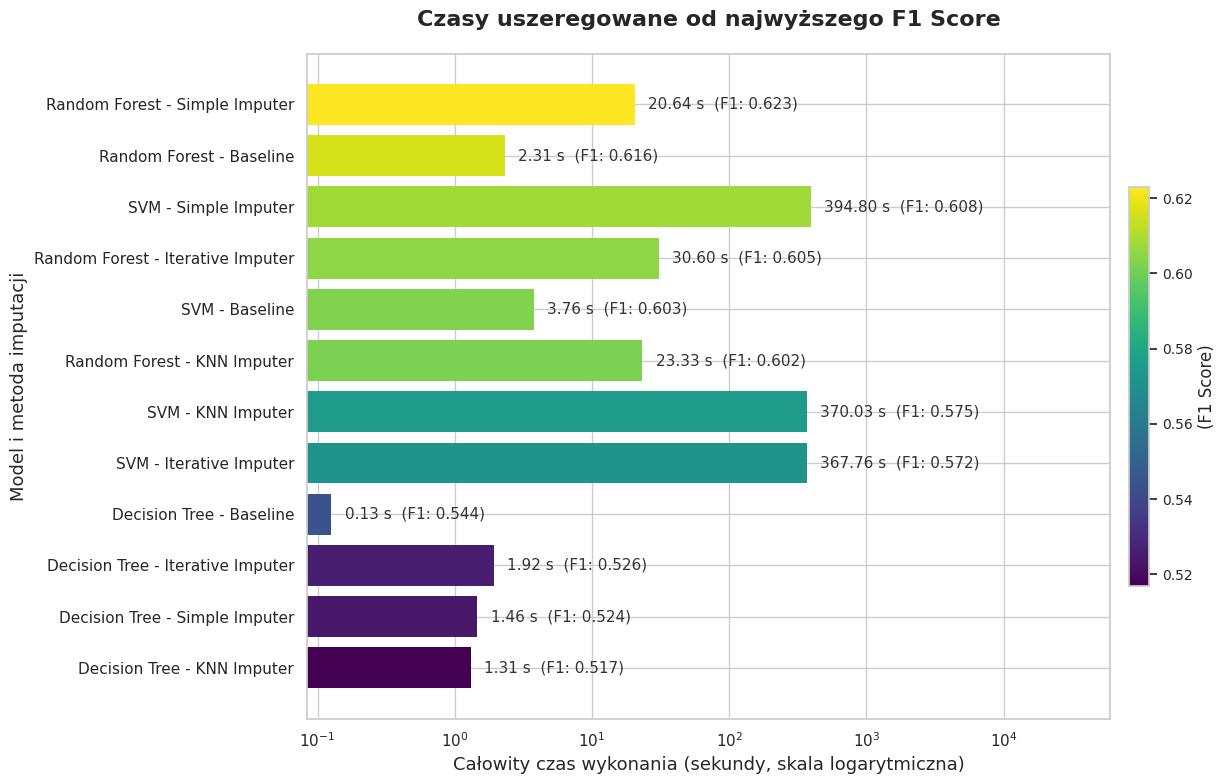

In [ ]:
df_plot = all_results.drop(columns=['Confusion matrix']).copy()
df_plot = df_plot.sort_values(by='F1', ascending=False).reset_index(drop=True)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(13, 8))

norm = mcolors.Normalize(vmin=df_plot['F1'].min(), vmax=df_plot['F1'].max())
mapper = cm.ScalarMappable(norm=norm, cmap='viridis')
bar_colors = [mapper.to_rgba(v) for v in df_plot['F1']]

bars = ax.barh(df_plot['Model'], df_plot['Time'], color=bar_colors, edgecolor='none')

ax.set_xscale('log')

ax.invert_yaxis()

for i, bar in enumerate(bars):
    f1_val = df_plot.loc[i, 'F1']
    time_val = df_plot.loc[i, 'Time']

    label_text = f"{time_val:.2f} s  (F1: {f1_val:.3f})"

    text_color = '#333333'
    weight = 'normal'

    ax.text(
        bar.get_width() * 1.25,
        bar.get_y() + bar.get_height()/2,
        label_text,
        va='center',
        ha='left',
        fontsize=11,
        color=text_color,
        weight=weight
    )

cbar = fig.colorbar(mapper, ax=ax, pad=0.02, shrink=0.6)
cbar.set_label('(F1 Score)', fontsize=12)
cbar.ax.tick_params(labelsize=10)

ax.set_title('Czasy uszeregowane od najwyższego F1 Score', fontsize=16, pad=20, weight='bold')
ax.set_xlabel('Całowity czas wykonania (sekundy, skala logarytmiczna)', fontsize=13)
ax.set_ylabel('Model i metoda imputacji', fontsize=13)

ax.set_xlim(right=df_plot['Time'].max() * 150)

plt.tight_layout()
plt.show()

Wykres przedstawia wszystkie dwanaście kombinacji modelu i metody imputacji, uszeregowanych malejąco według F1 Score, z zaznaczeniem całkowitego czasu treningu na skali logarytmicznej. Najlepszą jakość predykcji osiągnęła kombinacja Random Forest + Simple Imputer (F1 = 0.623), która przy czasie wykonania 23.77 s stanowi optymalne połączenie skuteczności i rozsądnego kosztu obliczeniowego. Jest to najlepsza kombinacja spośród wszystkich badanych i to ona zostaje wybrana jako rozwiązanie końcowe.
Istotnym problemem okazał się czas wykonania modelu SVM. Niezależnie od zastosowanej metody imputacji, SVM wymagał od kilkuset do ponad 450 sekund treningu (SVM + KNN Imputer: 423.93 s, SVM + Iterative Imputer: 453.25 s, SVM + Simple Imputer: 421.07 s). Jedynym wyjątkiem jest SVM + Baseline (4.05 s), jednak wynika to ze znacznie mniejszej liczby danych wykorzystywanych przez tę metodę, a nie z efektywności samego klasyfikatora. Przy tym SVM nie rekompensuje tego kosztu jakością — najlepszy wynik to F1 = 0.608, gorszy niż Random Forest.
Decision Tree, choć najszybszy (0.13–2.30 s), osiąga konsekwentnie najniższe wartości F1 (0.513–0.544) i nie stanowi konkurencyjnej alternatywy.

#10. Analiza wyników

##Obserwacje
Podsumowując wcześniej omówione obserwacje, przeprowadzone eksperymenty pokazały, że najlepsze wyniki uzyskała kombinacja Random Forest + Simple Imputer, osiągając F1 = 0.623. Model Random Forest charakteryzował się stabilnym działaniem niezależnie od zastosowanej metody imputacji, różnice między nimi były minimalne i nie przekraczały 0.018 punktu F1.
Model SVM osiągał zbliżone wyniki do Random Forest (najlepszy wynik F1 = 0.608), jednak jego praktyczne zastosowanie utrudnia bardzo długi czas treningu, sięgający nawet 453 sekund. Najsłabsze wyniki osiągał Decision Tree (F1 = 0.513–0.544), który nie wykazywał korzyści z zastosowania zaawansowanych metod imputacji.
We wszystkich modelach wpływ metody imputacji na jakość klasyfikacji okazał się ograniczony. Większe znaczenie miał wybór samego klasyfikatora. Metody bardziej zaawansowane (KNN Imputer, Iterative Imputer) nie przyniosły poprawy względem prostego Simple Imputer, generując jednocześnie wyższy koszt obliczeniowy.


## Wnioski
Analizie poddano trzy modele: Decision Tree, Random Forest oraz SVM, a także cztery podejścia do radzenia sobie z brakami danych: zbiór bazowy (Baseline), Simple Imputer, Iterative Imputer oraz KNN Imputer.
Przeprowadzone eksperymenty pokazały, że zastosowanie bardziej zaawansowanych metod imputacji nie doprowadziło do znaczącej poprawy jakości klasyfikacji. Modele wykorzystujące Iterative Imputer lub KNN Imputer osiągały wyniki porównywalne lub nieznacznie gorsze niż Simple Imputer, przy jednocześnie wyższym koszcie obliczeniowym.
Różnice pomiędziej metodami imputacji były zdecydowanie mniejsze niż różnice wynikające z wyboru klasyfikatora. To model miał decydujący wpływ na jakość predykcji. Najlepszym klasyfikatorem okazał się Random Forest, osiągając najwyższe F1 niezależnie od zastosowanej metody imputacji, przy rozsądnym czasie treningu. SVM, mimo zbliżonych wyników jakościowych, charakteryzował się bardzo długim czasem wykonania, co czyni go mniej praktycznym wyborem. Decision Tree wypadł najsłabiej pod względem F1 we wszystkich konfiguracjach.